# What does personalization add to the feed? A leakage-free ranking experiment on KuaiRand-1K

**AI in Industry — University of Bologna.** This notebook follows the two exploration notebooks
(`data_exploration_logs.ipynb`, `data_exploration_user_features.ipynb`) and the development proposal
(`Proposta_sviluppo_v1.md`). It turns the research question of the abstract into a single,
reproducible experiment.

**The decision we model.** A user of the single-column feed (tab 1) requests a block of about six
videos. The platform must decide in which order to show them. We ask:

1. *Main project.* How much does knowing **this particular user** improve the ordering of candidates,
   beyond what is known about the videos themselves (content and popularity)?
2. *3-ECTS extension.* Does the answer change when the objective is a **like** instead of a
   **long view**, and how many long views does a user's top 10 lose for each like gained when the two
   scores are blended?

## Ideas considered and the ones we kept

We brainstormed a longer list of directions and kept those that answer a precise question with the
data we have. The table records the reasoning, so the choice can be discussed.

| Idea | Question it answers | Decision |
|---|---|---|
| **Nested feature ladder A0 → A → B → C → D** with an L2 logistic regression | How much does each family of signals add? | **Kept** — core of the project (abstract + proposal). |
| **Strictly point-in-time features** (every feature uses only blocks *before* the impression) | Are the gains real or leakage? | **Kept** — a prerequisite. 98.7% of rows share their timestamp with other rows, so naive per-user rates leak the label. |
| **Within-block pairwise AUC** as the main ranking metric | Does the model order the candidates of the *same request* better? | **Kept** — it isolates the ranking decision; global AUC mostly rewards knowing *who* watches a lot. |
| **"Duration-only" baseline (A0)** | How much of the ranking is explained by the long-view rule itself (full watch needed below 18 s)? | **Kept** — cheap, and it guards against crediting personalization with a duration effect. |
| **Hierarchical popularity with fallback** video → author → tag → global | Can we score new videos (81% of test impressions)? | **Kept** — empirical-Bayes shrinkage; the user–tag smoothing weight is chosen on validation, the others are fixed. |
| **Personal duration taste** (user × duration-band rate) | Do users differ in their tolerance for long videos? | **Kept** as extension D3 — a personal signal that exists even for brand-new videos. |
| **Author affinity, recent history (72 h), repeated exposure** | Do the abstract's other personal signals add anything beyond topic preference? | **Kept** as D1, D2, D4, added one at a time. |
| **User-cluster bootstrap** for model differences | Is a gain larger than the noise between users? | **Kept**. |
| **Random-exposure log as a second test set** | Does the personal signal survive when exposure did not depend on the recommender? | **Kept** (pointwise metrics only: one random video per block). |
| **Gradient boosting** on the same features | Is the logistic model leaving non-linear signal on the table? | **Kept** as a check (scikit-learn `HistGradientBoostingClassifier`, same family as XGBoost). |
| **Like vs long-view blend at a common instant** | How much does the top 10 change, and what is the exchange rate? | **Kept** (3-ECTS part). Features are frozen at the start of each user-day so that all candidates are scored with the same information. |
| Profile features (`user_features_1k`) as predictors | — | **Dropped**: no timestamp, and the user's own past rate already captures stable differences (train/test correlation 0.93). |
| Monthly video statistics (`video_features_statistic`) | — | **Dropped as predictors**: they include the test period (leakage). Popularity is rebuilt from past logs instead. |
| Deep sequential recommenders (SASRec, DIN, …) | — | **Dropped**: outside the course, hard to explain at the oral exam, and the question is *which signal* matters, not the best possible score. |
| Counterfactual / IPS evaluation with the random log | — | **Parked**: the random log has one random video per block, too few to re-weight block rankings. |

## 0. Configuration

Every path, window, seed and parameter lives in this cell. The notebook runs top to bottom on a
laptop with ~8 GB of RAM (about 20–30 minutes the first time; the expensive feature tables are cached on disk
outside the OneDrive folder, so later runs are faster). On Colab set `ROOT = Path("/content")`.

In [1]:
from pathlib import Path
import gc, json, os, tarfile, tempfile, time, urllib.request, warnings
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import log_loss, roc_auc_score, average_precision_score

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

ROOT = Path(".")                                   # Colab: Path("/content")
DATA_DIR = ROOT / "KuaiRand-1K" / "data"
DATA_URL = "https://zenodo.org/records/10439422/files/KuaiRand-1K.tar.gz"
CACHE_DIR = Path(tempfile.gettempdir()) / "kuairand_cache"   # outside OneDrive on purpose
USE_CACHE = True

SEED = 42
TAB = 1                      # single-column feed (see the exploration notebook)
TRAIN_END = 20220421         # last day of the training window
FIT_START = 20220412         # rows before this day only feed the history (warm-up of 4 days)
VAL_START = 20220419         # chronological validation: 19-21 April
POOL_BLOCK_FRACTION = 0.40   # share of training blocks used to fit the models (memory)
SESSION_GAP_MS = 30 * 60 * 1000
RECENT_MS = 72 * 3600 * 1000 # "recent history" window of extension D2
M_GRID = [5, 20, 80, 320]        # candidate smoothing weights for the user-tag rate (chosen on validation)
M_TAG, M_AUTHOR, M_VIDEO, M_USER, M_UA, M_UD = 200, 20, 20, 20, 10, 20   # fixed smoothing weights
N_BOOT = 1000                # user-cluster bootstrap replicates
TRADEOFF_USER_DAYS = 3000    # user-days sampled for the like / long-view trade-off
MIN_CANDIDATES = 20          # a user-day needs at least this many distinct videos to define a top 10
TOP_K = 10

CACHE_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEED)
T_START = time.time()
print("Cache:", CACHE_DIR)

Cache: C:\Users\filip\AppData\Local\Temp\kuairand_cache


In [2]:
# Download and extract the dataset if it is not already there (same logic as the exploration notebooks).
if not DATA_DIR.exists():
    archive = ROOT / "KuaiRand-1K.tar.gz"
    if not archive.exists():
        print("Downloading KuaiRand-1K (~1 GB)...")
        urllib.request.urlretrieve(DATA_URL, archive)
    with tarfile.open(archive) as tar:
        tar.extractall(ROOT)
print(sorted(p.name for p in DATA_DIR.glob("*.csv")))

['log_random_4_22_to_5_08_1k.csv', 'log_standard_4_08_to_4_21_1k.csv', 'log_standard_4_22_to_5_08_1k.csv', 'user_features_1k.csv', 'video_features_basic_1k.csv', 'video_features_statistic_1k.csv']


## 1. Data

We read only the columns we need, with compact types, and keep **tab 1** only (66% of the standard
log, 991 users). Columns that reveal the outcome of the current impression (`play_time_ms`, `is_click`,
comments, …) are never used as features. The duration (`duration_ms`) is known before the video is
played, so it is a legitimate feature; a value of 0 means *missing*, not *zero seconds*.

In [3]:
LOG_COLS = ["user_id", "video_id", "date", "hourmin", "time_ms", "is_like", "long_view", "duration_ms", "tab"]
LOG_DTYPES = {"user_id": "int16", "video_id": "int32", "date": "int32", "hourmin": "int16",
              "time_ms": "int64", "is_like": "int8", "long_view": "int8", "duration_ms": "int32", "tab": "int8"}


def load_log(path, tab=TAB):
    parts = []
    for chunk in pd.read_csv(path, usecols=LOG_COLS, dtype=LOG_DTYPES, chunksize=2_000_000):
        parts.append(chunk.loc[chunk["tab"] == tab].drop(columns="tab"))
    return pd.concat(parts, ignore_index=True)


std = pd.concat([load_log(DATA_DIR / "log_standard_4_08_to_4_21_1k.csv"),
                 load_log(DATA_DIR / "log_standard_4_22_to_5_08_1k.csv")], ignore_index=True)
n_raw = len(std)
std = (std.drop_duplicates(["user_id", "video_id", "time_ms"])
          .sort_values(["user_id", "time_ms"], kind="stable").reset_index(drop=True))
rand = load_log(DATA_DIR / "log_random_4_22_to_5_08_1k.csv")

# Videos that appear anywhere (any tab) in the training window: defines the "new video" cohort.
train_video_ids = pd.read_csv(DATA_DIR / "log_standard_4_08_to_4_21_1k.csv", usecols=["video_id"],
                              dtype={"video_id": "int32"})["video_id"].unique()

print(f"Standard tab-1 rows: {n_raw:,} -> {len(std):,} after removing {n_raw - len(std)} exact duplicates")
print(f"Random tab-1 rows:   {len(rand):,}  (users {rand.user_id.nunique()}, videos {rand.video_id.nunique():,})")
print(f"Videos seen in the training window (all tabs): {len(train_video_ids):,}")

Standard tab-1 rows: 7,717,601 -> 7,717,596 after removing 5 exact duplicates
Random tab-1 rows:   42,636  (users 988, videos 7,377)
Videos seen in the training window (all tabs): 2,119,510


### Video metadata

`video_features_basic` is joined many-to-one on `video_id`. We keep the author, the upload date and
format, and up to two tags per video (videos with three or more tags are rare; we keep the first two).
The row count is checked before and after the join.

In [4]:
needed = np.union1d(std["video_id"].unique(), rand["video_id"].unique())
meta_parts = []
for chunk in pd.read_csv(DATA_DIR / "video_features_basic_1k.csv",
                         usecols=["video_id", "author_id", "upload_dt", "upload_type", "tag"],
                         dtype={"video_id": "int32", "author_id": "int64", "upload_dt": "string",
                                "upload_type": "string", "tag": "string"}, chunksize=500_000):
    meta_parts.append(chunk.loc[chunk["video_id"].isin(needed)])
meta = pd.concat(meta_parts).set_index("video_id")
del meta_parts

tag_str = meta["tag"].fillna("")
tag_split = tag_str.str.split(",", expand=True)
meta["tag1"] = pd.to_numeric(tag_split[0], errors="coerce").fillna(-1).astype("int16")
meta["tag2"] = pd.to_numeric(tag_split[1], errors="coerce").fillna(-1).astype("int16")
meta["n_tags"] = np.where(tag_str.eq(""), 0, tag_str.str.count(",") + 1).astype("int8")
EPOCH = pd.Timestamp("2022-01-01")
meta["upload_day"] = (pd.to_datetime(meta["upload_dt"], errors="coerce") - EPOCH).dt.days.astype("float32")
assert meta["tag1"].max() < 128 and meta["author_id"].max() < 10**8
meta["author_id"] = meta["author_id"].astype("int32")
meta = meta.drop(columns=["tag", "upload_dt"])

print(f"Metadata rows matched: {len(meta):,} of {len(needed):,} needed video ids")
print("Tag count per video (share of matched videos):",
      meta["n_tags"].value_counts(normalize=True).sort_index().round(4).to_dict())


def attach_meta(log):
    n_before = len(log)
    out = log.join(meta, on="video_id")
    assert len(out) == n_before, "the join must be many-to-one"
    return out


std, rand = attach_meta(std), attach_meta(rand)
print(f"Rows without metadata: standard {std['author_id'].isna().sum()}, random {rand['author_id'].isna().sum()}")

Metadata rows matched: 2,741,383 of 2,741,383 needed video ids
Tag count per video (share of matched videos): {0: 0.0311, 1: 0.7574, 2: 0.2068, 3: 0.0046, 4: 0.0001}


Rows without metadata: standard 0, random 0


### Derived columns known *before* the impression

* `dur_bin` — duration band (missing, ≤7 s, 7–12, 12–18, 18–30, 30–60, 60–120, 120–300, >300 s). The
  18 s boundary matters: below it a long view requires watching the entire video.
* `dur_grp` — four coarse bands used for the personal duration taste (missing, ≤18 s, 18–60 s, >60 s).
* `age_days` — days between upload and impression.
* `hour_idx` — absolute hour index; popularity features are updated **hourly**, using data up to the start of the current hour (a lag of 0–60 minutes),
  like a batch feature store.
* Upload format: the 8 most frequent formats, the rest grouped as `Other`.

In [5]:
DUR_EDGES_S = [0, 7, 12, 18, 30, 60, 120, 300, np.inf]
DUR_LABELS = ["missing", "<=7s", "7-12s", "12-18s", "18-30s", "30-60s", "60-120s", "120-300s", ">300s"]
DUR_GRP_LABELS = ["missing", "<=18s", "18-60s", ">60s"]
UPLOAD_TYPES = std["upload_type"].value_counts().index[:8].tolist()
date_to_day = {}


def add_derived(log):
    sec = log["duration_ms"].to_numpy() / 1000.0
    pos = sec > 0
    dur_bin = np.zeros(len(log), dtype="int8")
    dur_bin[pos] = np.digitize(sec[pos], DUR_EDGES_S[1:-1], right=True) + 1
    log["dur_bin"] = dur_bin
    grp = np.zeros(len(log), dtype="int8")
    grp[pos] = np.where(sec[pos] <= 18, 1, np.where(sec[pos] <= 60, 2, 3))
    log["dur_grp"] = grp
    days = {d: (pd.Timestamp(str(d)) - EPOCH).days for d in np.unique(log["date"])}
    date_to_day.update(days)
    log["day"] = log["date"].map(days).astype("int16")
    log["age_days"] = (log["day"] - log["upload_day"]).clip(lower=0).astype("float32")
    log["hour_idx"] = (log["time_ms"] // 3_600_000).astype("int64")
    log["utype"] = pd.Categorical(np.where(log["upload_type"].isin(UPLOAD_TYPES), log["upload_type"], "Other"))
    log.drop(columns=["upload_type"], inplace=True)
    return log


std, rand = add_derived(std), add_derived(rand)
std["is_new_video"] = ~std["video_id"].isin(train_video_ids)
rand["is_new_video"] = ~rand["video_id"].isin(train_video_ids)
print(std.memory_usage(deep=True).sum() / 2**20, "MiB for the standard tab-1 log")
std.head()

419.5250720977783 MiB for the standard tab-1 log


,user_id,video_id,date,hourmin,time_ms,is_like,long_view,duration_ms,author_id,tag1,tag2,n_tags,upload_day,dur_bin,dur_grp,day,age_days,hour_idx,utype,is_new_video
0,0,3173641,20220409,1100,1649475132652,0,0,95833,4332456,19,-1,1,96.0,6,3,98,2.0,458187,Kmovie,False
1,0,889528,20220409,1100,1649475132652,0,0,20040,4565021,28,-1,1,98.0,4,2,98,0.0,458187,Web,False
2,0,2650549,20220409,1100,1649475132652,0,0,8333,2015742,2,-1,1,96.0,2,1,98,2.0,458187,ShortImport,False
3,0,2497952,20220409,1200,1649477382190,0,0,0,2863194,26,-1,1,74.0,0,0,98,24.0,458188,LongPicture,False
4,0,2675156,20220409,1200,1649477382190,0,0,177666,7539201,39,-1,1,94.0,7,3,98,4.0,458188,Web,False


### Blocks and sessions

A **block** is the set of rows of the same user with the same `time_ms`: the videos delivered by one
request. Their viewing order inside the block is unknown, so all features of a row are computed from
**strictly earlier blocks**. A **session** is a run of blocks separated by gaps shorter than 30 minutes;
the position of the block in its session is a context feature (identical for all candidates of a block).

In [6]:
blocks = (std.groupby(["user_id", "time_ms"], sort=True)
             .agg(n=("long_view", "size"), k_lv=("long_view", "sum"), k_like=("is_like", "sum"))
             .reset_index())
gap = blocks.groupby("user_id")["time_ms"].diff()
blocks["session_id"] = (gap.isna() | (gap > SESSION_GAP_MS)).cumsum()
blocks["sess_pos"] = blocks.groupby("session_id").cumcount().astype("int32")
std["block_id"] = std.groupby(["user_id", "time_ms"], sort=True).ngroup().astype("int32")
std["sess_pos"] = blocks["sess_pos"].to_numpy()[std["block_id"].to_numpy()]
print(f"Blocks: {len(blocks):,}   sessions: {blocks.session_id.nunique():,}   "
      f"median block size: {blocks.n.median():.0f}")

Blocks: 1,439,000   sessions: 134,411   median block size: 6


## 2. Point-in-time features

### The mechanism

For each *entity* (a user, a (user, tag) pair, a video, …) we build a table of **cumulative** counts
after each block: impressions `n`, long views `k_lv`, likes `k_like`. To obtain the history available
at query time `t`, we look up the last row of the table **strictly before** `t`
(`pd.merge_asof(..., allow_exact_matches=False)`). The same function serves the training rows, the test
rows, the random log and the "common instant" used later, so there is a single code path to check.

Popularity tables (tag, author, video) are aggregated by hour and looked up strictly before the current
hour. User-level tables use the exact block time.

The history is built from **standard tab-1 impressions only**. Random impressions are evaluated but never
added to the history (they are 0.5% of the test rows).

In [7]:
VALS = ["n", "k_lv", "k_like"]


def cum_table(keys, times, lv, like):
    """Cumulative (n, k_lv, k_like) per key after each distinct time, sorted by key then time."""
    ev = pd.DataFrame({"key": keys.astype("int64"), "t": times.astype("int64"),
                       "n": np.ones(len(keys), dtype="int32"), "k_lv": lv.astype("int32"),
                       "k_like": like.astype("int32")})
    g = ev.groupby(["key", "t"], sort=True)[VALS].sum()
    c = g.groupby(level=0).cumsum().astype("float32").reset_index()
    return c


def asof_lookup(q_keys, q_times, table, n_chunks=8):
    """History strictly before q_times for each q_keys (zeros when the key has no earlier record)."""
    q_keys = np.asarray(q_keys, dtype="int64")
    q_times = np.asarray(q_times, dtype="int64")
    out = np.zeros((len(q_keys), 3), dtype="float32")
    t_keys = table["key"].to_numpy()
    edges = np.unique(np.quantile(t_keys, np.linspace(0, 1, n_chunks + 1)[1:-1]))
    q_chunk = np.searchsorted(edges, q_keys, side="right")
    t_chunk = np.searchsorted(edges, t_keys, side="right")
    for c in range(len(edges) + 1):
        qi = np.flatnonzero(q_chunk == c)
        if len(qi) == 0:
            continue
        left = pd.DataFrame({"key": q_keys[qi], "t": q_times[qi], "_i": qi}).sort_values("t", kind="stable")
        right = table.loc[t_chunk == c].sort_values("t", kind="stable")
        m = pd.merge_asof(left, right, on="t", by="key", allow_exact_matches=False, direction="backward")
        out[m["_i"].to_numpy()] = m[VALS].fillna(0).to_numpy("float32")
    return out


# Entity keys (int64). Tags are < 128, authors < 1e8, videos < 1e7.
def k_user(d):        return d["user_id"].to_numpy("int64")
def k_user_tag(d, c): return d["user_id"].to_numpy("int64") * 128 + d[c].to_numpy("int64")
def k_user_author(d): return d["user_id"].to_numpy("int64") * 10**8 + d["author_id"].to_numpy("int64")
def k_user_dur(d):    return d["user_id"].to_numpy("int64") * 8 + d["dur_grp"].to_numpy("int64")
def k_user_video(d):  return d["user_id"].to_numpy("int64") * 10**7 + d["video_id"].to_numpy("int64")


lv, like = std["long_view"].to_numpy(), std["is_like"].to_numpy()
t_ms, t_h = std["time_ms"].to_numpy(), std["hour_idx"].to_numpy()

# User-tag events: one event per (impression, tag).
has1, has2 = std["tag1"].to_numpy() >= 0, std["tag2"].to_numpy() >= 0
ut_keys = np.concatenate([k_user_tag(std, "tag1")[has1], k_user_tag(std, "tag2")[has2]])
ut_t = np.concatenate([t_ms[has1], t_ms[has2]])
ut_lv = np.concatenate([lv[has1], lv[has2]])
ut_like = np.concatenate([like[has1], like[has2]])
tag_keys = np.concatenate([std["tag1"].to_numpy("int64")[has1], std["tag2"].to_numpy("int64")[has2]])
tag_h = np.concatenate([t_h[has1], t_h[has2]])

TABLE_SPECS = {
    # name: (builder of the cumulative table)
    "user":  lambda: cum_table(k_user(std), t_ms, lv, like),
    "ut":    lambda: cum_table(ut_keys, ut_t, ut_lv, ut_like),
    "ua":    lambda: cum_table(k_user_author(std), t_ms, lv, like),
    "ud":    lambda: cum_table(k_user_dur(std), t_ms, lv, like),
    "uv":    lambda: cum_table(k_user_video(std), t_ms, lv, like),
    "tagpop": lambda: cum_table(tag_keys, tag_h, ut_lv, ut_like),
    "authpop": lambda: cum_table(std["author_id"].to_numpy("int64"), t_h, lv, like),
    "vidpop": lambda: cum_table(std["video_id"].to_numpy("int64"), t_h, lv, like),
}


def compute_raw(Q, tables_needed=None):
    """Raw history counts for the query frame Q (columns user_id, video_id, author_id, tag1, tag2,
    dur_grp, t, h). Returns a DataFrame of float32 columns '<level>_<n|k_lv|k_like>'."""
    raw = {}

    def put(name, arr):
        for j, v in enumerate(VALS):
            raw[f"{name}_{v}"] = arr[:, j]

    qt, qh = Q["t"].to_numpy("int64"), Q["h"].to_numpy("int64")
    q1, q2 = Q["tag1"].to_numpy() >= 0, Q["tag2"].to_numpy() >= 0
    for name, build in TABLE_SPECS.items():
        t0 = time.time()
        table = build()
        if name == "user":
            put("user", asof_lookup(k_user(Q), qt, table))
            put("user_old", asof_lookup(k_user(Q), qt - RECENT_MS, table))
        elif name == "ut":
            for c, mask in (("tag1", q1), ("tag2", q2)):
                keys = k_user_tag(Q, c)
                a, b = asof_lookup(keys, qt, table), asof_lookup(keys, qt - RECENT_MS, table)
                a[~mask], b[~mask] = 0, 0
                put(f"ut{c[-1]}", a); put(f"ut{c[-1]}_old", b)
        elif name == "ua":
            put("ua", asof_lookup(k_user_author(Q), qt, table))
        elif name == "ud":
            put("ud", asof_lookup(k_user_dur(Q), qt, table))
        elif name == "uv":
            put("uv", asof_lookup(k_user_video(Q), qt, table))
        elif name == "tagpop":
            for c, mask in (("tag1", q1), ("tag2", q2)):
                a = asof_lookup(Q[c].to_numpy("int64"), qh, table)
                a[~mask] = 0
                put(f"tp{c[-1]}", a)
        elif name == "authpop":
            put("ap", asof_lookup(Q["author_id"].to_numpy("int64"), qh, table))
        elif name == "vidpop":
            put("vp", asof_lookup(Q["video_id"].to_numpy("int64"), qh, table))
        del table; gc.collect()
        print(f"  {name:8s} done in {time.time() - t0:5.1f}s")
    return pd.DataFrame(raw)

### Query frames

* **pool** — a 40% sample of the training blocks between 12 and 21 April (rows from 8–11 April only feed
  the history). Its 12–18 April part is used to fit models during model selection and its 19–21 April
  part for chronological validation; the final models are refitted on the whole pool.
* **test** — every standard tab-1 row from 22 April to 8 May.
* **random** — every random tab-1 row (22 April – 8 May).

Sampling *blocks* (not rows) keeps all candidates of a request together, which the ranking metric needs.

In [8]:
block_keep = rng.random(len(blocks)) < POOL_BLOCK_FRACTION
in_pool = (std["date"].between(FIT_START, TRAIN_END)) & block_keep[std["block_id"].to_numpy()]
in_test = std["date"] > TRAIN_END

Q_COLS = ["user_id", "video_id", "author_id", "tag1", "tag2", "n_tags", "dur_bin", "dur_grp", "age_days",
          "utype", "date", "day", "upload_day", "hourmin", "time_ms", "hour_idx", "sess_pos", "long_view", "is_like", "is_new_video"]
Q_std = std.loc[in_pool | in_test, Q_COLS + ["block_id"]].copy()
Q_std["split"] = np.where(Q_std["date"] > TRAIN_END, "test",
                          np.where(Q_std["date"] >= VAL_START, "val", "fit"))

# Session position of random rows: the block of the standard feed they were inserted into (or the last
# block before them).
rq = rand.sort_values("time_ms")
pos = pd.merge_asof(rq[["user_id", "time_ms"]].reset_index(), blocks[["user_id", "time_ms", "sess_pos"]]
                    .sort_values("time_ms"), on="time_ms", by="user_id", direction="backward")
rand.loc[pos["index"].to_numpy(), "sess_pos"] = pos["sess_pos"].fillna(0).to_numpy()
Q_rand = rand[Q_COLS].copy()
Q_rand["block_id"] = -1
Q_rand["split"] = "random"

Q = pd.concat([Q_std, Q_rand], ignore_index=True)
Q["t"], Q["h"] = Q["time_ms"], Q["hour_idx"]
del Q_std, Q_rand; gc.collect()
print(Q["split"].value_counts().to_string())

split
test      4431299
fit        645202
val        268233
random      42636


In [9]:
raw_path = CACHE_DIR / f"raw_main_seed{SEED}_pool{POOL_BLOCK_FRACTION}.parquet"
if USE_CACHE and raw_path.exists():
    R = pd.read_parquet(raw_path)
    print("Loaded cached raw history counts:", R.shape)
else:
    t0 = time.time()
    R = compute_raw(Q)
    R.to_parquet(raw_path)
    print(f"Raw history counts {R.shape} computed in {time.time() - t0:.0f}s")
assert len(R) == len(Q)

Loaded cached raw history counts: (5387370, 39)


### Leakage checks

Before modelling we verify the mechanism on the data:

1. For 300 random query rows we recompute the user–tag history **by brute force** (filtering the raw
   log on `time_ms < t`) and compare it with the looked-up value.
2. The same brute-force check on the overall user history.
3. Rows of the same block must share the same user history (simultaneous events share the same past).

In [10]:
check_idx = rng.choice(np.flatnonzero((Q["split"] != "random") & (Q["tag1"] >= 0)), 300, replace=False)
by_user = {u: g for u, g in std[["user_id", "time_ms", "tag1", "tag2", "long_view"]].groupby("user_id")}
mismatch = 0
for i in check_idx:
    row = Q.iloc[i]
    g = by_user[row.user_id]
    past = g[(g.time_ms < row.t) & ((g.tag1 == row.tag1) | (g.tag2 == row.tag1))]
    mismatch += (len(past) != R["ut1_n"].iat[i]) or (past.long_view.sum() != R["ut1_k_lv"].iat[i])
print(f"Brute-force user-tag history mismatches: {mismatch} / {len(check_idx)}")

user_mismatch = 0
for i in check_idx[:100]:
    row = Q.iloc[i]
    g = by_user[row.user_id]
    user_mismatch += int((g.time_ms < row.t).sum() != R["user_n"].iat[i])
print(f"Brute-force user history mismatches: {user_mismatch} / 100")
same_block_spread = (R.loc[Q["block_id"] >= 0, "user_n"]
                     .groupby(Q.loc[Q["block_id"] >= 0, "block_id"]).nunique().max())
print("Max distinct user-history values inside one block:", same_block_spread)
assert mismatch == 0 and user_mismatch == 0 and same_block_spread == 1
del by_user
# From here on the raw log is only needed to rebuild history tables: keep the key columns only.
std = std[["user_id", "video_id", "author_id", "dur_grp"]]
gc.collect()

Brute-force user-tag history mismatches: 0 / 300
Brute-force user history mismatches: 0 / 100


Max distinct user-history values inside one block: 1


7

### From counts to features

Rare counts are smoothed with an empirical-Bayes rule: with `k` positives in `n` past impressions,
the rate is `(k + m·p) / (n + m)`, where `p` is the rate of the parent level and `m` its weight. This
gives a **hierarchical fallback**: a video with no history inherits its author's rate, an unknown
author inherits the tag rate, an untagged video inherits the global rate `p0`.

Personal rates are expressed as a **deviation in log-odds from the user's own overall rate**: a value
of +0.5 on `ut_dev` means "this user long-views this tag more than they usually long-view anything".
This separates *taste* (C, D) from *general propensity* (B). Supports enter as `log1p(n)`.

| Group | Features | Varies within a block? |
|---|---|---|
| **A0 · content** | duration band, upload format, video age | yes |
| **A · + popularity** | tag rate, author rate (→ tag), video rate (→ author), their supports | yes |
| **B · + user propensity** | user overall rate and support, position in session, hour of day | **no** |
| **C · + user–tag taste** | deviation of the user's tag rate, support, share of the user's history on that tag | yes |
| **D1 · author affinity** | user–author deviation, support, "has already liked this author" | yes |
| **D2 · recent history (72 h)** | recent user deviation (block-constant), recent user–tag deviation and support | partly |
| **D3 · duration taste** | user × duration-band deviation and support | yes |
| **D4 · repeated exposure** | times the video was already shown to the user, already long-viewed | yes |

B is block-constant on purpose: in an additive logistic model it can change *who* is predicted to watch,
but not the order of one user's candidates. It is the control that shows the difference between
predicting individuals and ranking candidates.

In [11]:
def logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))


def shrink(k, n, prior, m):
    return (k + m * prior) / (n + m)


def make_features(R, Q, target, m_ut, p0):
    """Feature matrix (float32 DataFrame) for target in {'lv', 'like'}."""
    k = f"k_{target}"
    F = {}
    # --- A0: content
    for b in range(1, len(DUR_LABELS)):
        F[f"dur_{DUR_LABELS[b]}"] = (Q["dur_bin"].to_numpy() == b)
    for u in UPLOAD_TYPES[1:] + ["Other"]:
        F[f"fmt_{u}"] = (Q["utype"].to_numpy() == u)
    age = Q["age_days"].to_numpy()
    F["age_missing"] = np.isnan(age)
    F["age_log"] = np.log1p(np.nan_to_num(age, nan=0.0))
    # --- A: population popularity with hierarchical fallback
    h1, h2 = Q["tag1"].to_numpy() >= 0, Q["tag2"].to_numpy() >= 0
    r1 = shrink(R[f"tp1_{k}"].to_numpy(), R["tp1_n"].to_numpy(), p0, M_TAG)
    r2 = shrink(R[f"tp2_{k}"].to_numpy(), R["tp2_n"].to_numpy(), p0, M_TAG)
    tag_rate = np.where(h1 & h2, (r1 + r2) / 2, np.where(h1, r1, p0))
    F["no_tag"] = ~h1
    F["tag_pop"] = logit(tag_rate)
    ra = shrink(R[f"ap_{k}"].to_numpy(), R["ap_n"].to_numpy(), tag_rate, M_AUTHOR)
    F["author_pop"] = logit(ra)
    F["author_pop_n"] = np.log1p(R["ap_n"].to_numpy())
    rv = shrink(R[f"vp_{k}"].to_numpy(), R["vp_n"].to_numpy(), ra, M_VIDEO)
    F["video_pop"] = logit(rv)
    F["video_pop_n"] = np.log1p(R["vp_n"].to_numpy())
    # --- B: user propensity and context (block-constant)
    n_u = R["user_n"].to_numpy()
    ru = shrink(R[f"user_{k}"].to_numpy(), n_u, p0, M_USER)
    F["user_rate"] = logit(ru)
    F["user_n"] = np.log1p(n_u)
    F["sess_pos"] = np.log1p(Q["sess_pos"].to_numpy())
    hour = (Q["hourmin"].to_numpy() // 100) * 2 * np.pi / 24
    F["hour_sin"], F["hour_cos"] = np.sin(hour), np.cos(hour)
    # --- C: user-tag taste
    def tag_dev(n1, k1, n2, k2, m):
        d1 = logit(shrink(k1, n1, ru, m)) - logit(ru)
        d2 = logit(shrink(k2, n2, ru, m)) - logit(ru)
        dev = np.where(h1 & h2, (d1 + d2) / 2, np.where(h1, d1, 0.0))
        sup = np.where(h1 & h2, (n1 + n2) / 2, np.where(h1, n1, 0.0))
        return dev, sup
    col = lambda c: R[c].to_numpy()
    dev, sup = tag_dev(col("ut1_n"), col(f"ut1_{k}"), col("ut2_n"), col(f"ut2_{k}"), m_ut)
    F["ut_dev"], F["ut_n"], F["ut_share"] = dev, np.log1p(sup), sup / np.maximum(n_u, 1)
    # --- D1: author affinity
    n_ua = R["ua_n"].to_numpy()
    F["ua_dev"] = logit(shrink(R[f"ua_{k}"].to_numpy(), n_ua, ru, M_UA)) - logit(ru)
    F["ua_n"] = np.log1p(n_ua)
    F["ua_liked_before"] = R["ua_k_like"].to_numpy() > 0
    # --- D2: recent history (last 72 h) = history(t) - history(t - 72 h)
    n72 = n_u - R["user_old_n"].to_numpy()
    k72 = R[f"user_{k}"].to_numpy() - R[f"user_old_{k}"].to_numpy()
    F["recent_user_dev"] = logit(shrink(k72, n72, ru, M_USER)) - logit(ru)
    F["recent_user_n"] = np.log1p(n72)
    dev72, sup72 = tag_dev(col("ut1_n") - col("ut1_old_n"), col(f"ut1_{k}") - col(f"ut1_old_{k}"),
                           col("ut2_n") - col("ut2_old_n"), col(f"ut2_{k}") - col(f"ut2_old_{k}"), m_ut)
    F["recent_ut_dev"], F["recent_ut_n"] = dev72, np.log1p(sup72)
    # --- D3: duration taste
    n_ud = R["ud_n"].to_numpy()
    F["ud_dev"] = logit(shrink(R[f"ud_{k}"].to_numpy(), n_ud, ru, M_UD)) - logit(ru)
    F["ud_n"] = np.log1p(n_ud)
    # --- D4: repeated exposure
    F["uv_n"] = np.log1p(R["uv_n"].to_numpy())
    F["uv_pos_before"] = R[f"uv_{k}"].to_numpy() > 0
    return pd.DataFrame({c: np.asarray(v, dtype="float32") for c, v in F.items()})


GROUPS = {
    "A0": [f"dur_{l}" for l in DUR_LABELS[1:]] + [f"fmt_{u}" for u in UPLOAD_TYPES[1:] + ["Other"]]
          + ["age_missing", "age_log"],
    "A":  ["no_tag", "tag_pop", "author_pop", "author_pop_n", "video_pop", "video_pop_n"],
    "B":  ["user_rate", "user_n", "sess_pos", "hour_sin", "hour_cos"],
    "C":  ["ut_dev", "ut_n", "ut_share"],
    "D1": ["ua_dev", "ua_n", "ua_liked_before"],
    "D2": ["recent_user_dev", "recent_user_n", "recent_ut_dev", "recent_ut_n"],
    "D3": ["ud_dev", "ud_n"],
    "D4": ["uv_n", "uv_pos_before"],
}
LADDER = {
    "A0 content":         ["A0"],
    "A popularity":       ["A0", "A"],
    "B +user propensity": ["A0", "A", "B"],
    "C +user-tag taste":  ["A0", "A", "B", "C"],
    "C+D1 author":        ["A0", "A", "B", "C", "D1"],
    "C+D2 recent 72h":    ["A0", "A", "B", "C", "D2"],
    "C+D3 duration taste": ["A0", "A", "B", "C", "D3"],
    "C+D4 repeats":       ["A0", "A", "B", "C", "D4"],
    "D all":              ["A0", "A", "B", "C", "D1", "D2", "D3", "D4"],
}
cols_of = lambda name: [c for g in LADDER[name] for c in GROUPS[g]]

## 3. Evaluation tools

* **Log-loss** and **prevalence** — quality of the probabilities.
* **Global AUC** — pools all impressions: it rewards a model that knows *which users* watch a lot.
* **User AUC** — AUC computed within each user (users with both outcomes), averaged with equal weight.
* **Block AUC (main ranking metric)** — within each request block with at least one positive and one
  negative, the share of (positive, negative) pairs in which the positive gets the higher score (ties
  count ½), averaged with equal weight per block. It compares candidates *at the same moment*.
* **Uncertainty** — 95% intervals from a **user-cluster bootstrap**: users are resampled with replacement
  and all their blocks move together; two models are always compared on the *same* resampled users.

In [12]:
def group_auc(group, y, s):
    """Per-group AUC via ranks (ties = 1/2). Returns DataFrame [group, auc, n_pos, n_neg] for mixed groups."""
    d = pd.DataFrame({"g": group, "y": y.astype("int8"), "s": s})
    stats = d.groupby("g")["y"].agg(["sum", "size"])
    mixed = stats.index[(stats["sum"] > 0) & (stats["sum"] < stats["size"])]
    d = d[d["g"].isin(mixed)]
    d["r"] = d.groupby("g")["s"].rank(method="average")
    agg = d.assign(rp=d["r"] * d["y"]).groupby("g").agg(rp=("rp", "sum"), P=("y", "sum"), n=("y", "size"))
    agg["N"] = agg["n"] - agg["P"]
    agg["auc"] = (agg["rp"] - agg["P"] * (agg["P"] + 1) / 2) / (agg["P"] * agg["N"])
    return agg[["auc", "P", "N"]]


def unit_table(df, score, unit):
    """Per-unit AUC table with the owning user, for the bootstrap. unit in {'block', 'user'}."""
    g = df["block_id"].to_numpy() if unit == "block" else df["user_id"].to_numpy()
    t = group_auc(g, df["y"].to_numpy(), score)
    if unit == "block":
        owner = df.groupby("block_id")["user_id"].first()
        t["user_id"] = owner.reindex(t.index).to_numpy()
    else:
        t["user_id"] = t.index
    return t


def boot_mean(tables, n_boot=N_BOOT, seed=SEED):
    """User-cluster bootstrap of the mean unit AUC for one or more aligned unit tables.
    Returns (point estimates, replicate matrix [n_boot, n_tables])."""
    users = np.unique(tables[0]["user_id"])
    uidx = {u: i for i, u in enumerate(users)}
    S, C = [], []
    for t in tables:
        ui = t["user_id"].map(uidx).to_numpy()
        S.append(np.bincount(ui, weights=t["auc"].to_numpy(), minlength=len(users)))
        C.append(np.bincount(ui, minlength=len(users)).astype(float))
    S, C = np.array(S), np.array(C)
    r = np.random.default_rng(seed)
    W = r.multinomial(len(users), np.full(len(users), 1 / len(users)), size=n_boot).astype(float)
    reps = (W @ S.T) / (W @ C.T)
    return S.sum(1) / C.sum(1), reps


def ci(x):
    return np.percentile(x, [2.5, 97.5])


def pointwise(y, p):
    return {"prevalence": y.mean(), "mean_pred": p.mean(), "logloss": log_loss(y, p, labels=[0, 1]),
            "auc": roc_auc_score(y, p), "ap": average_precision_score(y, p)}

## 4. Model selection on the chronological validation split

We fit the C model (the central comparison) on 12–18 April and evaluate on 19–21 April, for each
smoothing weight `m` of the user–tag rate. The weight with the best validation **block AUC** is kept for
all models; the other weights are fixed a priori (they act on levels with much more data).
The L2 strength is the scikit-learn default (`C = 1` on standardized features): with ~10⁶ rows and ~40
features it barely matters, which the second table checks.

In [13]:
def fit_logit(X, y, C=1.0):
    model = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=1000))
    return model.fit(X, y)


def predict(model, X, batch=1_000_000):
    return np.concatenate([model.predict_proba(X.iloc[i:i + batch])[:, 1] for i in range(0, len(X), batch)])


split = Q["split"].to_numpy()
is_fit, is_val, is_pool = split == "fit", split == "val", np.isin(split, ["fit", "val"])
is_test, is_rand = split == "test", split == "random"
Y = {"lv": Q["long_view"].to_numpy(), "like": Q["is_like"].to_numpy()}
P0 = {t: Y[t][is_fit].mean() for t in Y}          # global prior from the fitting rows only
print({t: round(float(v), 4) for t, v in P0.items()})

val_rows = []
best_m = {}
for target in ("lv", "like"):
    for m in M_GRID:
        F = make_features(R, Q, target, m, P0[target])
        cols = cols_of("C +user-tag taste")
        model = fit_logit(F.loc[is_fit, cols], Y[target][is_fit])
        p = predict(model, F.loc[is_val, cols])
        dv = Q.loc[is_val, ["block_id", "user_id"]].assign(y=Y[target][is_val])
        bt = unit_table(dv, p, "block")
        val_rows.append({"target": target, "m": m, "val_logloss": log_loss(Y[target][is_val], p),
                         "val_block_auc": bt["auc"].mean(), "blocks": len(bt)})
        del F; gc.collect()
    vt = pd.DataFrame([r for r in val_rows if r["target"] == target])
    best_m[target] = int(vt.loc[vt["val_block_auc"].idxmax(), "m"])
val_table = pd.DataFrame(val_rows)
display(val_table.round(4))
print("Chosen user-tag smoothing weight:", best_m)

{'lv': 0.3238, 'like': 0.0188}


,target,m,val_logloss,val_block_auc,blocks
0,lv,5,0.5375,0.6369,33120
1,lv,20,0.5374,0.6370,33120
2,lv,80,0.5378,0.6373,33120
3,lv,320,0.5388,0.6364,33120
4,like,5,0.0483,0.7014,2679
5,like,20,0.0481,0.7016,2679
6,like,80,0.0481,0.7025,2679
7,like,320,0.0484,0.7015,2679


Chosen user-tag smoothing weight: {'lv': 80, 'like': 80}


In [14]:
# Sensitivity to the L2 strength (long view, C model, chosen m).
F = make_features(R, Q, "lv", best_m["lv"], P0["lv"])
cols = cols_of("C +user-tag taste")
dv = Q.loc[is_val, ["block_id", "user_id"]].assign(y=Y["lv"][is_val])
reg_rows = []
for Creg in (0.001, 1.0):
    p = predict(fit_logit(F.loc[is_fit, cols], Y["lv"][is_fit], C=Creg), F.loc[is_val, cols])
    reg_rows.append({"C (inverse L2)": Creg, "val_logloss": log_loss(Y["lv"][is_val], p),
                     "val_block_auc": unit_table(dv, p, "block")["auc"].mean()})
display(pd.DataFrame(reg_rows).round(5))
del F; gc.collect()

,C (inverse L2),val_logloss,val_block_auc
0,0.001,0.53801,0.63737
1,1.000,0.53782,0.63728


44

## 5. Main experiment: the feature ladder on the test period (long view)

Each model of the ladder is refitted on the whole pool (12–21 April) with the chosen smoothing and then
frozen. Feature *values* keep updating during the test period (an online feature store), model
*weights* do not. All models are evaluated on exactly the same impressions.

In [15]:
def std_coefs(model, cols):
    """Coefficients of the logistic step: change in log-odds per standard deviation of each feature."""
    return pd.Series(model[-1].coef_[0], index=cols)


EVAL_COLS = ["user_id", "block_id", "split", "video_id", "tag1", "tag2", "dur_bin", "is_new_video",
             "long_view", "is_like", "time_ms", "date"]
is_eval = is_test | is_rand
E = Q.loc[is_eval, EVAL_COLS].reset_index(drop=True)
e_test, e_rand = (E["split"] == "test").to_numpy(), (E["split"] == "random").to_numpy()


def run_ladder(target):
    F = make_features(R, Q, target, best_m[target], P0[target])
    models, preds = {}, {}
    for name in LADDER:
        t0 = time.time()
        cols = cols_of(name)
        models[name] = fit_logit(F.loc[is_pool, cols], Y[target][is_pool])
        preds[name] = predict(models[name], F.loc[is_eval, cols]).astype("float32")
        print(f"  {target:4s} {name:22s} fitted in {time.time() - t0:5.1f}s")
    # keep a few raw supports for the analyses
    extra = F.loc[is_eval, ["ut_n", "user_n", "ut_dev", "tag_pop", "video_pop", "ud_dev"]].reset_index(drop=True)
    return F, models, pd.DataFrame(preds), extra


F_lv, models_lv, P_lv, X_lv = run_ladder("lv")

  lv   A0 content             fitted in   5.4s


  lv   A popularity           fitted in   5.8s


  lv   B +user propensity     fitted in   4.9s


  lv   C +user-tag taste      fitted in   5.9s


  lv   C+D1 author            fitted in   6.0s


  lv   C+D2 recent 72h        fitted in   9.1s


  lv   C+D3 duration taste    fitted in  10.8s


  lv   C+D4 repeats           fitted in   7.1s


  lv   D all                  fitted in   8.6s


In [16]:
def ladder_report(P, target, ref_pairs):
    y = E[{"lv": "long_view", "like": "is_like"}[target]].to_numpy()
    dt = E.loc[e_test, ["block_id", "user_id"]].assign(y=y[e_test])
    dr = E.loc[e_rand, ["block_id", "user_id"]].assign(y=y[e_rand])
    rows, blk_tabs, usr_tabs, rnd_tabs = [], {}, {}, {}
    for name in P.columns:
        p = P[name].to_numpy()
        st, rd = pointwise(y[e_test], p[e_test]), pointwise(y[e_rand], p[e_rand])
        blk_tabs[name] = unit_table(dt, p[e_test], "block")
        usr_tabs[name] = unit_table(dt, p[e_test], "user")
        rnd_tabs[name] = unit_table(dr, p[e_rand], "user")
        rows.append({"model": name,
                     "std logloss": st["logloss"], "std AUC": st["auc"], "std AP": st["ap"],
                     "std user-AUC": usr_tabs[name]["auc"].mean(), "std block-AUC": blk_tabs[name]["auc"].mean(),
                     "rand logloss": rd["logloss"], "rand AUC": rd["auc"], "rand AP": rd["ap"],
                     "rand user-AUC": rnd_tabs[name]["auc"].mean()})
    table = pd.DataFrame(rows).set_index("model")
    names = list(P.columns)
    _, rep_blk = boot_mean([blk_tabs[n] for n in names])
    _, rep_rnd = boot_mean([rnd_tabs[n] for n in names])
    _, rep_usr = boot_mean([usr_tabs[n] for n in names])
    table["block-AUC 95% CI"] = [f"[{a:.4f}, {b:.4f}]" for a, b in (ci(rep_blk[:, i]) for i in range(len(names)))]
    diffs = []
    for new, old in ref_pairs:
        i, j = names.index(new), names.index(old)
        d_blk = blk_tabs[new]["auc"].mean() - blk_tabs[old]["auc"].mean()
        d_rnd = rnd_tabs[new]["auc"].mean() - rnd_tabs[old]["auc"].mean()
        d_usr = usr_tabs[new]["auc"].mean() - usr_tabs[old]["auc"].mean()
        lo, hi = ci(rep_blk[:, i] - rep_blk[:, j]); rlo, rhi = ci(rep_rnd[:, i] - rep_rnd[:, j])
        ulo, uhi = ci(rep_usr[:, i] - rep_usr[:, j])
        diffs.append({"comparison": f"{new}  −  {old}",
                      "Δ std block-AUC": d_blk, "95% CI (std block)": f"[{lo:+.4f}, {hi:+.4f}]",
                      "Δ std user-AUC": d_usr, "95% CI (std user)": f"[{ulo:+.4f}, {uhi:+.4f}]",
                      "Δ rand user-AUC": d_rnd, "95% CI (rand user)": f"[{rlo:+.4f}, {rhi:+.4f}]"})
    info = {"std blocks (mixed outcomes)": len(blk_tabs[names[0]]),
            "std users with blocks": blk_tabs[names[0]]["user_id"].nunique(),
            "rand users with both outcomes": len(rnd_tabs[names[0]]),
            "std prevalence": y[e_test].mean(), "rand prevalence": y[e_rand].mean()}
    return table, pd.DataFrame(diffs).set_index("comparison"), blk_tabs, info


PAIRS = [("A popularity", "A0 content"), ("B +user propensity", "A popularity"),
         ("C +user-tag taste", "B +user propensity"), ("C+D1 author", "C +user-tag taste"),
         ("C+D2 recent 72h", "C +user-tag taste"), ("C+D3 duration taste", "C +user-tag taste"),
         ("C+D4 repeats", "C +user-tag taste"), ("D all", "C +user-tag taste"), ("D all", "B +user propensity")]
lv_table, lv_diffs, lv_blk, lv_info = ladder_report(P_lv, "lv", PAIRS)
print(lv_info)
display(lv_table.drop(columns=["std AP", "rand AP"]).round(4))
display(lv_diffs.round(4))

{'std blocks (mixed outcomes)': 546586, 'std users with blocks': 990, 'rand users with both outcomes': 693, 'std prevalence': np.float64(0.31466800141448364), 'rand prevalence': np.float64(0.08476404916033399)}


,std logloss,std AUC,std user-AUC,std block-AUC,rand logloss,rand AUC,rand user-AUC,block-AUC 95% CI
model,,,,,,,,
A0 content,0.6081,0.5915,0.5859,0.5859,0.4913,0.5254,0.5461,"[0.5829, 0.5895]"
A popularity,0.5867,0.6616,0.6284,0.6222,0.4929,0.5756,0.5891,"[0.6188, 0.6261]"
B +user propensity,0.5363,0.7489,0.6421,0.6308,0.5396,0.7271,0.6148,"[0.6274, 0.6344]"
C +user-tag taste,0.5321,0.7539,0.6502,0.6392,0.5067,0.7452,0.6579,"[0.6360, 0.6428]"
C+D1 author,0.5310,0.7554,0.6530,0.6431,0.5018,0.7456,0.6609,"[0.6399, 0.6467]"
C+D2 recent 72h,0.5286,0.7578,0.6533,0.6398,0.4898,0.7456,0.6609,"[0.6366, 0.6434]"
C+D3 duration taste,0.5311,0.7552,0.6526,0.6420,0.5076,0.7465,0.6578,"[0.6387, 0.6455]"
C+D4 repeats,0.5320,0.7540,0.6505,0.6393,0.5070,0.7451,0.6575,"[0.6361, 0.6428]"
D all,0.5265,0.7604,0.6582,0.6459,0.4854,0.7477,0.6632,"[0.6427, 0.6494]"


,Δ std block-AUC,95% CI (std block),Δ std user-AUC,95% CI (std user),Δ rand user-AUC,95% CI (rand user)
comparison,,,,,,
A popularity − A0 content,0.0363,"[+0.0341, +0.0385]",0.0425,"[+0.0409, +0.0443]",0.0430,"[+0.0261, +0.0589]"
B +user propensity − A popularity,0.0085,"[+0.0077, +0.0093]",0.0136,"[+0.0121, +0.0151]",0.0257,"[+0.0166, +0.0346]"
C +user-tag taste − B +user propensity,0.0085,"[+0.0074, +0.0096]",0.0081,"[+0.0072, +0.0092]",0.0431,"[+0.0349, +0.0513]"
C+D1 author − C +user-tag taste,0.0039,"[+0.0034, +0.0043]",0.0028,"[+0.0025, +0.0030]",0.0030,"[+0.0004, +0.0059]"
C+D2 recent 72h − C +user-tag taste,0.0006,"[+0.0005, +0.0007]",0.0031,"[+0.0025, +0.0037]",0.0030,"[-0.0025, +0.0086]"
C+D3 duration taste − C +user-tag taste,0.0027,"[+0.0023, +0.0033]",0.0024,"[+0.0019, +0.0030]",-0.0001,"[-0.0042, +0.0042]"
C+D4 repeats − C +user-tag taste,0.0001,"[-0.0000, +0.0002]",0.0003,"[+0.0002, +0.0004]",-0.0004,"[-0.0016, +0.0004]"
D all − C +user-tag taste,0.0067,"[+0.0060, +0.0073]",0.0080,"[+0.0072, +0.0089]",0.0053,"[-0.0014, +0.0122]"
D all − B +user propensity,0.0151,"[+0.0137, +0.0165]",0.0161,"[+0.0147, +0.0177]",0.0484,"[+0.0387, +0.0587]"


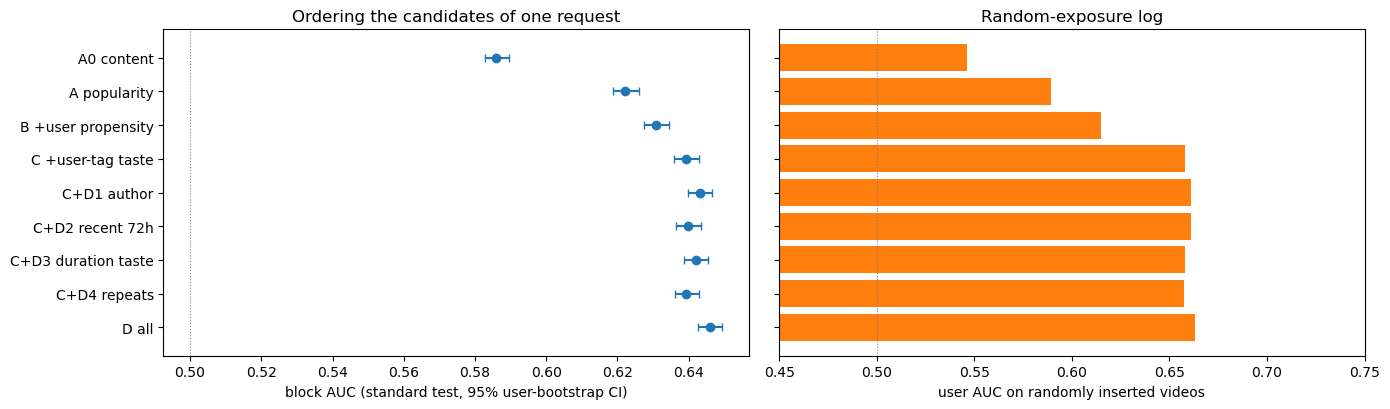

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
names = list(P_lv.columns)
_, rep = boot_mean([lv_blk[n] for n in names])
est = [lv_blk[n]["auc"].mean() for n in names]
lo, hi = np.percentile(rep, 2.5, axis=0), np.percentile(rep, 97.5, axis=0)
axes[0].errorbar(est, range(len(names)), xerr=[np.array(est) - lo, hi - np.array(est)], fmt="o", capsize=3)
axes[0].axvline(0.5, color="grey", lw=0.8, ls=":")
axes[0].set(yticks=range(len(names)), yticklabels=names, xlabel="block AUC (standard test, 95% user-bootstrap CI)",
            title="Ordering the candidates of one request")
axes[0].invert_yaxis()
axes[1].barh(range(len(names)), lv_table["rand user-AUC"], color="tab:orange")
axes[1].axvline(0.5, color="grey", lw=0.8, ls=":")
axes[1].set(xlim=(0.45, max(0.75, lv_table["rand user-AUC"].max() + 0.02)),
            xlabel="user AUC on randomly inserted videos", title="Random-exposure log")
plt.tight_layout(); plt.show()

### 5.0 Diagnostics and robustness of the ladder

**Why can B change the order of candidates?** B adds only block-constant features, which cannot reorder
candidates *for fixed coefficients*. Any within-block change must therefore come from the **re-estimated
coefficients of the A features** once user propensity is controlled for. We compare them directly.

**Is there more personal taste to exploit outside the feed?** One hypothesis is that the recommender,
by selecting videos the user is expected to like, compresses the spread of the user–tag deviation among
feed candidates. We test it by comparing the dispersion on standard and random impressions.

In [18]:
a_cols = cols_of("A popularity")
coef_ab = pd.DataFrame({"model A": std_coefs(models_lv["A popularity"], a_cols),
                        "model B": std_coefs(models_lv["B +user propensity"], a_cols + GROUPS["B"])[a_cols]})
coef_ab["change"] = coef_ab["model B"] - coef_ab["model A"]
display(coef_ab.loc[GROUPS["A"]].round(3))
print("Largest absolute change among all A features:",
      coef_ab["change"].abs().idxmax(), round(float(coef_ab["change"].abs().max()), 3))

disp = pd.DataFrame({
    "standard test": X_lv.loc[e_test, "ut_dev"].describe(percentiles=[0.1, 0.5, 0.9]),
    "random log": X_lv.loc[e_rand, "ut_dev"].describe(percentiles=[0.1, 0.5, 0.9])}).T
disp["within-user SD"] = [X_lv.loc[m, "ut_dev"].groupby(E.loc[m, "user_id"]).std().median() for m in (e_test, e_rand)]
display(disp[["mean", "std", "10%", "50%", "90%", "within-user SD"]].round(3))

,model A,model B,change
no_tag,-0.002,-0.002,-0.000
tag_pop,0.017,0.043,0.026
author_pop,0.157,0.075,-0.082
author_pop_n,0.012,0.032,0.020
video_pop,0.310,0.228,-0.082
video_pop_n,0.080,0.011,-0.069


Largest absolute change among all A features: video_pop 0.082


,mean,std,10%,50%,90%,within-user SD
standard test,-0.018,0.363,-0.479,0.017,0.385,0.266
random log,-0.023,0.278,-0.339,-0.009,0.291,0.208


**Robustness of the ranking gains.** Three further checks on the standard test:

1. *Equal weight per user.* Block AUC gives every block the same weight, so very active users contribute
   many blocks. We also average the block AUC within each user first, then across users.
2. *A usable unit.* The share of mixed blocks whose **top-1 candidate** was actually long-viewed (random
   order gives the share of positives in the block).
3. *A within-block estimator.* The ladder is fitted pointwise, so part of what it learns concerns *which
   blocks* have many long views. We refit A, C and "D all" on features **demeaned within each block** (an
   approximation of a conditional logit). This estimator can only learn from contrasts between candidates
   of the same request, so B's features vanish and B ≡ A. For memory, the test uses a random 30% of the
   test blocks.

In [19]:
def per_user(tab):
    t = tab.groupby("user_id")["auc"].mean().to_frame()
    t["user_id"] = t.index
    return t


pu_names = ["A popularity", "B +user propensity", "C +user-tag taste", "D all"]
est, rep_ = boot_mean([per_user(lv_blk[n]) for n in pu_names])
rob = []
for n_new, n_old in (("B +user propensity", "A popularity"), ("C +user-tag taste", "B +user propensity"),
                     ("D all", "B +user propensity")):
    i, j = pu_names.index(n_new), pu_names.index(n_old)
    lo, hi = ci(rep_[:, i] - rep_[:, j])
    rob.append({"comparison": f"{n_new} − {n_old}", "user-weighted Δ block-AUC": est[i] - est[j],
                "95% CI": f"[{lo:+.4f}, {hi:+.4f}]"})
display(pd.DataFrame(rob).set_index("comparison").round(4))

# Top-1 hit rate on mixed blocks
mixed_blocks = lv_blk["A popularity"].index
tb = E.loc[e_test, ["block_id", "user_id", "long_view"]]
tb = tb[tb["block_id"].isin(mixed_blocks)]
share = tb.groupby("block_id").agg(auc=("long_view", "mean"), user_id=("user_id", "first"))
hit_tabs, hit_names = [share], ["random order"] + pu_names
for n in pu_names:
    sc = pd.Series(P_lv[n].to_numpy(), index=E.index).loc[tb.index]
    top1 = sc.groupby(tb["block_id"]).idxmax()
    hit = tb.loc[top1.to_numpy(), ["block_id", "user_id", "long_view"]].set_index("block_id")
    hit_tabs.append(hit.rename(columns={"long_view": "auc"}).reindex(share.index))
est, rep_ = boot_mean(hit_tabs)
hits = pd.DataFrame({"share of blocks whose top-1 is a long view": est,
                     "95% CI": [f"[{a:.4f}, {b:.4f}]" for a, b in (ci(rep_[:, i]) for i in range(len(hit_names)))]},
                    index=hit_names)
display(hits.round(4))
i_c, i_b, i_d = (hit_names.index(n) for n in ("C +user-tag taste", "B +user propensity", "D all"))
print(f"Top-1 hit rate: C − B {est[i_c] - est[i_b]:+.4f} {ci(rep_[:, i_c] - rep_[:, i_b]).round(4)}, "
      f"D all − B {est[i_d] - est[i_b]:+.4f} {ci(rep_[:, i_d] - rep_[:, i_b]).round(4)}")

,user-weighted Δ block-AUC,95% CI
comparison,,
B +user propensity − A popularity,0.0064,"[+0.0052, +0.0076]"
C +user-tag taste − B +user propensity,0.0098,"[+0.0084, +0.0111]"
D all − B +user propensity,0.0155,"[+0.0135, +0.0175]"


,share of blocks whose top-1 is a long view,95% CI
random order,0.4021,"[0.3934, 0.4104]"
A popularity,0.5149,"[0.5046, 0.5248]"
B +user propensity,0.5312,"[0.5215, 0.5410]"
C +user-tag taste,0.5401,"[0.5299, 0.5502]"
D all,0.5480,"[0.5383, 0.5575]"


Top-1 hit rate: C − B +0.0089 [0.0074 0.0105], D all − B +0.0169 [0.0149 0.0188]


In [20]:
# Within-block (demeaned) estimator on a random 30% of the test blocks
wb_rng = np.random.default_rng(SEED + 4)
test_blocks = np.unique(E.loc[e_test, "block_id"])
keep_blocks = wb_rng.choice(test_blocks, int(0.3 * len(test_blocks)), replace=False)
sel = e_test & E["block_id"].isin(keep_blocks).to_numpy()
rows_pool = np.flatnonzero(is_pool)
rows_test = np.flatnonzero(is_eval)[sel]
qb = Q["block_id"].to_numpy()


def demeaned(rows, cols):
    X = F_lv.loc[rows, cols]
    return X - X.groupby(qb[rows]).transform("mean")


d_sub = E.loc[sel, ["block_id", "user_id"]].assign(y=E.loc[sel, "long_view"].to_numpy())
wb_tabs = {}
for n in ("A popularity", "C +user-tag taste", "D all"):
    cols = cols_of(n)
    m_wb = fit_logit(demeaned(rows_pool, cols), Y["lv"][is_pool])
    wb_tabs[f"within-block {n}"] = unit_table(d_sub, predict(m_wb, demeaned(rows_test, cols)), "block")
    wb_tabs[f"pointwise {n}"] = unit_table(d_sub, P_lv[n].to_numpy()[sel], "block")
    gc.collect()
names_wb = list(wb_tabs)
est, rep_ = boot_mean([wb_tabs[n] for n in names_wb])
display(pd.DataFrame({"block AUC (30% of test blocks)": est}, index=names_wb).round(4))
for kind in ("within-block", "pointwise"):
    for new, old in (("C +user-tag taste", "A popularity"), ("D all", "C +user-tag taste"), ("D all", "A popularity")):
        i, j = names_wb.index(f"{kind} {new}"), names_wb.index(f"{kind} {old}")
        lo, hi = ci(rep_[:, i] - rep_[:, j])
        print(f"{kind:12s} {new} − {old}: {est[i] - est[j]:+.4f} [{lo:+.4f}, {hi:+.4f}]")

,block AUC (30% of test blocks)
within-block A popularity,0.6334
pointwise A popularity,0.6230
within-block C +user-tag taste,0.6423
pointwise C +user-tag taste,0.6401
within-block D all,0.6471
pointwise D all,0.6463


within-block C +user-tag taste − A popularity: +0.0089 [+0.0078, +0.0102]
within-block D all − C +user-tag taste: +0.0048 [+0.0040, +0.0056]
within-block D all − A popularity: +0.0138 [+0.0122, +0.0155]
pointwise    C +user-tag taste − A popularity: +0.0171 [+0.0157, +0.0187]
pointwise    D all − C +user-tag taste: +0.0062 [+0.0054, +0.0070]
pointwise    D all − A popularity: +0.0233 [+0.0215, +0.0253]


**Reading the ladder (long view).** The test covers 4.43 M standard impressions (546,586 blocks with
mixed outcomes, 990 users) and 42,636 random impressions (693 users with both outcomes).

* **Content and popularity do most of the ranking work.** Duration and format alone reach a block AUC of
  0.586. Adding popularity with the video → author → tag fallback brings it to 0.622 (+0.036, the
  largest single step). This popularity is estimated from only 1,000 users, so it is a weak version of what a platform would have. Against a stronger popularity baseline, the personal gains below could differ.
* **Predicting *who* watches is not the same as ranking *what* to show.** User propensity (B) is the
  biggest improvement in log-loss (0.587 → 0.536) and in global AUC (0.662 → 0.749): it tells the model
  which users watch a lot. B's features are identical for all candidates of a block, so they cannot
  reorder candidates for fixed coefficients. B's +0.0085 in block AUC is a **fitting effect**: controlling
  for the user changes the estimated weights of the popularity features (an omitted-variable correction,
  §5.0). It is not a personal signal. The value of personalization is therefore measured **from B**:
  "D all" − B.
* **Personal taste reorders the feed by a small but clearly non-zero amount.** C − B = **+0.0085**
  [0.0074, 0.0096] in block AUC. "D all" − B = **+0.015** [0.014, 0.017]. Author affinity (+0.0039) and
  duration taste (+0.0027) are the useful extensions. The 72-hour history adds almost nothing to ranking
  (+0.0006), although it improves log-loss: its main term is block-constant. Repeated exposure is too rare
  to matter (+0.0001, CI includes 0).
* **The user–tag signal is much stronger on random exposures.** To compare like with like we use the same
  metric, user AUC, on both test sets: C − B is +0.0081 [0.0072, 0.0092] on the standard feed and **+0.043**
  [0.035, 0.051] on randomly inserted videos, about five times larger. When the recommender did not choose
  the video, the user's tag history separates watched from skipped videos much better. Part of this may be
  mechanical: the user–tag support and share also record how often the recommender itself served that tag,
  which says nothing new inside the feed but is informative about a random video. Author affinity transfers
  weakly (+0.0030 [0.0004, 0.0059]). Duration taste and repeats do not transfer.
* **A warning on probabilities.** Adding user propensity *worsens* the random-log log-loss (0.493 → 0.540).
  Propensities learned on a feed with a 31% long-view rate are over-confident on random videos (8.5%).
  §5.3 shows the calibration gap.

**Robustness (§5.0).**

* *Fitting effect of B.* Model B shifts weight from video and author popularity to the tag rate (video
  popularity 0.31 → 0.23, author 0.16 → 0.08).
* *Within-block estimator.* With features demeaned inside each block, B's terms vanish by construction,
  yet the within-block A model already reaches 0.633, against 0.623 for the pointwise A. The personal gains
  survive this estimator: C − A = +0.0089 [0.0078, 0.0102] and "D all" − A = +0.0138 [0.0122, 0.0155].
  The pointwise and within-block "D all" end up at the same ranking quality (0.646 vs 0.647).
* *Equal weight per user.* C − B = +0.0098 and "D all" − B = +0.0155. The gains are not driven by the few
  very active users who contribute most blocks.
* *In a usable unit.* The first candidate of a block is a long view 40.2% of the time in random order,
  51.5% with popularity, 53.1% with B and 54.8% with "D all". That is +1.7 points [1.5, 1.9] from
  personalization (C: +0.9).
* *Dispersion hypothesis rejected.* The user–tag deviation is *less* dispersed among random videos than
  among feed candidates (within-user SD 0.21 vs 0.27). The larger gain on the random log is therefore not explained by the feed compressing taste. It reflects a stronger association between the user–tag features and the outcome on random videos, possibly including the exposure-frequency proxy noted above.

### 5.1 New videos versus videos with a history

81% of the test impressions concern videos never seen in the training window. We recompute the block
AUC **among new candidates only** (blocks restricted to their new videos, with at least one positive
and one negative left) and, separately, among videos already seen in training.

In [21]:
def cohort_block_auc(P, target, mask, models_to_show):
    y = E[{"lv": "long_view", "like": "is_like"}[target]].to_numpy()
    sel = e_test & mask
    d = E.loc[sel, ["block_id", "user_id"]].assign(y=y[sel])
    tabs = {n: unit_table(d, P[n].to_numpy()[sel], "block") for n in models_to_show}
    est, rep = boot_mean([tabs[n] for n in models_to_show])
    return tabs, est, rep


show = ["A0 content", "A popularity", "B +user propensity", "C +user-tag taste", "D all"]
rows = []
for label, mask in (("new videos", E["is_new_video"].to_numpy()), ("seen in training", ~E["is_new_video"].to_numpy())):
    tabs, est, rep = cohort_block_auc(P_lv, "lv", mask, show)
    row = {"cohort": label, "impressions": int((e_test & mask).sum()), "blocks": len(tabs[show[0]])}
    for i, n in enumerate(show):
        row[n] = est[i]
    iC, iB, iD = show.index("C +user-tag taste"), show.index("B +user propensity"), show.index("D all")
    lo, hi = ci(rep[:, iC] - rep[:, iB]); row["C − B"] = f"{est[iC] - est[iB]:+.4f} [{lo:+.4f}, {hi:+.4f}]"
    lo, hi = ci(rep[:, iD] - rep[:, iB]); row["D all − B"] = f"{est[iD] - est[iB]:+.4f} [{lo:+.4f}, {hi:+.4f}]"
    rows.append(row)
cohort_table = pd.DataFrame(rows).set_index("cohort")
display(cohort_table.round(4))

,impressions,blocks,A0 content,A popularity,B +user propensity,C +user-tag taste,D all,C − B,D all − B
cohort,,,,,,,,,
new videos,3574567,480206,0.5933,0.6293,0.6369,0.6454,0.6521,"+0.0085 [+0.0074, +0.0097]","+0.0152 [+0.0137, +0.0167]"
seen in training,856732,106225,0.5536,0.5989,0.6062,0.6136,0.6187,"+0.0074 [+0.0054, +0.0094]","+0.0125 [+0.0102, +0.0150]"


**New videos are where personalization is used.** Among candidates never seen in training (3.57 M
impressions, 480 k blocks), C − B = +0.0085 [0.0074, 0.0097] and "D all" − B = +0.0152. These gains are
similar to those on videos with a training history (+0.0074 [0.0054, 0.0094] and +0.0125); the intervals
overlap. The personal features describe the *user's* reaction to tags, authors and durations, so a new
video inherits them on its first impression. All models rank already-seen videos less well (0.61 vs 0.65).
We have not tested why.

### 5.2 When does personalization help? Gain by amount of personal history

For each test block we take the mean user–tag support of its candidates (how many past impressions the
user had on those tags) and the user's total history. The block-AUC gain of C and of "D all" over B is
plotted per bin, with user-bootstrap intervals.

,blocks,users,B block-AUC,C +user-tag taste − B,C +user-tag taste lo,C +user-tag taste hi,D all − B,D all lo,D all hi
bin,,,,,,,,,
≤10,1010,133,0.6578,0.0056,-0.0032,0.0166,-0.0006,-0.0120,0.0106
10–50,9576,493,0.6525,0.0095,0.0052,0.0131,0.0132,0.0086,0.0181
50–200,68465,898,0.6484,0.0089,0.0074,0.0105,0.0135,0.0117,0.0151
200–1000,307126,827,0.6342,0.0084,0.0070,0.0101,0.0149,0.0131,0.0171
>1000,160409,429,0.6152,0.0084,0.0066,0.0102,0.0164,0.0142,0.0188


,blocks,users,B block-AUC,C +user-tag taste − B,C +user-tag taste lo,C +user-tag taste hi,D all − B,D all lo,D all hi
bin,,,,,,,,,
≤500,5958,174,0.6504,0.0092,0.0044,0.0136,0.0120,0.0055,0.0181
500–2k,42311,434,0.6465,0.0100,0.0080,0.0121,0.0141,0.0115,0.0165
2k–5k,131159,587,0.6406,0.0101,0.0085,0.0118,0.0164,0.0146,0.0186
5k–10k,179007,481,0.6303,0.0088,0.0071,0.0106,0.0147,0.0128,0.0171
>10k,188151,251,0.6202,0.0067,0.0050,0.0084,0.0149,0.0130,0.0170


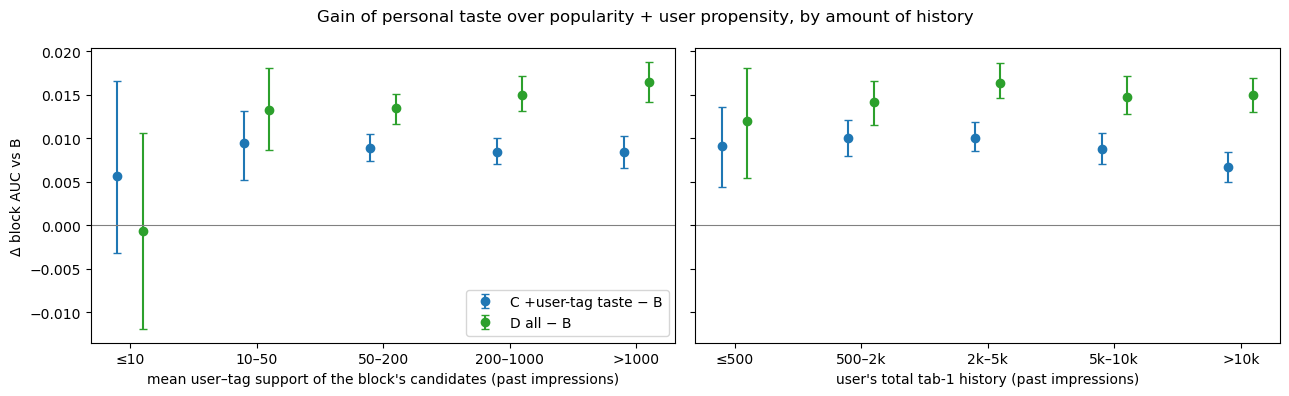

In [22]:
blk_ids = lv_blk["C +user-tag taste"].index
blk_info = pd.DataFrame({"block_id": E.loc[e_test, "block_id"].to_numpy(),
                         "ut_support": np.expm1(X_lv.loc[e_test, "ut_n"].to_numpy()),
                         "user_hist": np.expm1(X_lv.loc[e_test, "user_n"].to_numpy())}).groupby("block_id").mean()
blk_info = blk_info.reindex(blk_ids)
SUP_BINS, SUP_LBL = [-1, 10, 50, 200, 1000, np.inf], ["≤10", "10–50", "50–200", "200–1000", ">1000"]
HIST_BINS, HIST_LBL = [-1, 500, 2000, 5000, 10000, np.inf], ["≤500", "500–2k", "2k–5k", "5k–10k", ">10k"]


def gain_by(binvar, bins, labels, new_names=("C +user-tag taste", "D all"), base="B +user propensity"):
    b = pd.cut(blk_info[binvar], bins, labels=labels)
    out = []
    for lab in labels:
        sel = (b == lab).to_numpy()
        tabs = [lv_blk[base].loc[sel]] + [lv_blk[n].loc[sel] for n in new_names]
        est, rep = boot_mean(tabs, n_boot=400)
        row = {"bin": lab, "blocks": int(sel.sum()), "users": tabs[0]["user_id"].nunique(),
               "B block-AUC": est[0]}
        for i, n in enumerate(new_names, start=1):
            lo, hi = ci(rep[:, i] - rep[:, 0])
            row[f"{n} − B"], row[f"{n} lo"], row[f"{n} hi"] = est[i] - est[0], lo, hi
        out.append(row)
    return pd.DataFrame(out).set_index("bin")


g_sup = gain_by("ut_support", SUP_BINS, SUP_LBL)
g_hist = gain_by("user_hist", HIST_BINS, HIST_LBL)
display(g_sup.round(4)); display(g_hist.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, g, xl in ((axes[0], g_sup, "mean user–tag support of the block's candidates (past impressions)"),
                  (axes[1], g_hist, "user's total tab-1 history (past impressions)")):
    x = np.arange(len(g))
    for off, n, c in ((-0.1, "C +user-tag taste", "tab:blue"), (0.1, "D all", "tab:green")):
        ax.errorbar(x + off, g[f"{n} − B"], yerr=[g[f"{n} − B"] - g[f"{n} lo"], g[f"{n} hi"] - g[f"{n} − B"]],
                    fmt="o", capsize=3, color=c, label=f"{n} − B")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set(xticks=x, xticklabels=g.index, xlabel=xl)
axes[0].set_ylabel("Δ block AUC vs B"); axes[0].legend()
plt.suptitle("Gain of personal taste over popularity + user propensity, by amount of history")
plt.tight_layout(); plt.show()

**Where the personal signal helps.**

* *By user–tag support.* The gain of C over B is roughly constant, about +0.008 to +0.010, from 10 past
  impressions on the candidate tags upward. Below 10 the bin is small (1,010 blocks) and the interval
  includes zero. Consistent with the shrinkage towards the user's own rate, the ≤10 bin shows no loss. The gain of
  "D all" increases with support (+0.013 → +0.016). Support is strongly tied to user activity, so this
  pattern cannot be attributed to support alone.
* *By user activity.* All models order the feed of very active users less well (B block AUC falls from
  0.650 to 0.620). The user–tag gain is largest for moderately active users (2k–5k past impressions:
  +0.010) and smallest for the heaviest (>10k: +0.007). The richer "D all" profile keeps a gain of about
  +0.015 for every activity level above 500 impressions.

### 5.3 Calibration on the two test sets

A model trained on the recommender's feed sees a 31% long-view rate; random insertions have 8.5%. We
compare predicted and observed rates by decile of prediction.

standard test  observed 0.315  mean predicted 0.319  top-decile observed 0.701 vs predicted 0.707
random log     observed 0.085  mean predicted 0.354  top-decile observed 0.254 vs predicted 0.696


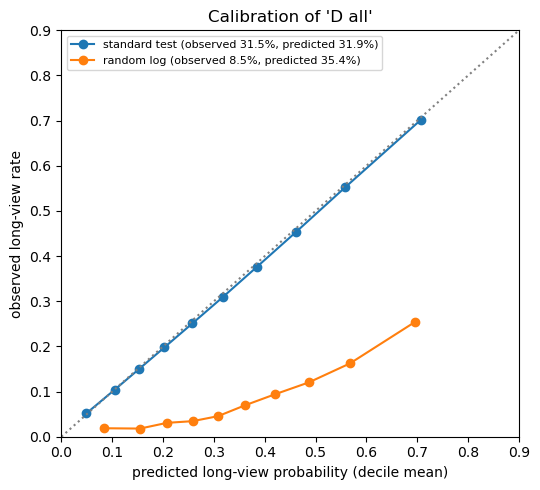

In [23]:
fig, ax = plt.subplots(figsize=(5.5, 5))
y_lv = E["long_view"].to_numpy()
for mask, lab, c in ((e_test, "standard test", "tab:blue"), (e_rand, "random log", "tab:orange")):
    p = P_lv["D all"].to_numpy()[mask]; yy = y_lv[mask]
    q = pd.qcut(p, 10, duplicates="drop")
    cal = pd.DataFrame({"p": p, "y": yy}).groupby(q, observed=True).mean()
    ax.plot(cal["p"], cal["y"], "o-", color=c, label=f"{lab} (observed {yy.mean():.1%}, predicted {p.mean():.1%})")
    print(f"{lab:14s} observed {yy.mean():.3f}  mean predicted {p.mean():.3f}  "
          f"top-decile observed {cal['y'].iloc[-1]:.3f} vs predicted {cal['p'].iloc[-1]:.3f}")
ax.plot([0, 1], [0, 1], ":", color="grey")
ax.set(xlabel="predicted long-view probability (decile mean)", ylabel="observed long-view rate",
       title="Calibration of 'D all'", xlim=(0, 0.9), ylim=(0, 0.9))
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Ranking transfers, probabilities do not.** On the standard test the model is well calibrated: it predicts
0.319 on average against 0.315 observed, and 0.707 against 0.701 in the top decile. On random exposures it
predicts 0.354 on average against 0.085 observed, and 0.696 against 0.254 in the top decile. The model has
learned the long-view rate *of videos the recommender chose*. The ordering still carries over (user AUC
0.66 on random), but the probabilities should be recalibrated before being compared with a threshold, a
business rule, or the like score on an absolute scale.

### 5.4 Is the logistic model leaving non-linear signal on the table?

Durations, supports and deviations may interact (a personal deviation is more reliable with more
support; the long-view rule changes at 18 s). We fit a gradient-boosted tree ensemble
(`HistGradientBoostingClassifier`, the scikit-learn analogue of XGBoost/LightGBM) on the **same "D all"
features and rows**, with early stopping on an internal 10% split, and compare on the same test blocks.

In [24]:
t0 = time.time()
cols_all = cols_of("D all")
hgb = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.08, max_leaf_nodes=63, min_samples_leaf=200,
                                     l2_regularization=1.0, early_stopping=True, validation_fraction=0.1,
                                     n_iter_no_change=20, random_state=SEED)
hgb.fit(F_lv.loc[is_pool, cols_all], Y["lv"][is_pool])
p_hgb = hgb.predict_proba(F_lv.loc[is_eval, cols_all])[:, 1]
print(f"HGB fitted in {time.time() - t0:.0f}s with {hgb.n_iter_} iterations")

dt = E.loc[e_test, ["block_id", "user_id"]].assign(y=y_lv[e_test])
dr = E.loc[e_rand, ["block_id", "user_id"]].assign(y=y_lv[e_rand])
cmp_rows = []
tabs_std = {"logistic D all": lv_blk["D all"], "boosting D all": unit_table(dt, p_hgb[e_test], "block")}
tabs_rnd = {"logistic D all": unit_table(dr, P_lv["D all"].to_numpy()[e_rand], "user"),
            "boosting D all": unit_table(dr, p_hgb[e_rand], "user")}
_, rs = boot_mean(list(tabs_std.values())); _, rr = boot_mean(list(tabs_rnd.values()))
for i, (n, p) in enumerate((("logistic D all", P_lv["D all"].to_numpy()), ("boosting D all", p_hgb))):
    cmp_rows.append({"model": n, "std logloss": log_loss(y_lv[e_test], p[e_test]),
                     "std block-AUC": tabs_std[n]["auc"].mean(), "rand logloss": log_loss(y_lv[e_rand], p[e_rand]),
                     "rand user-AUC": tabs_rnd[n]["auc"].mean()})
cmp = pd.DataFrame(cmp_rows).set_index("model")
display(cmp.round(4))
lo, hi = ci(rs[:, 1] - rs[:, 0]); rlo, rhi = ci(rr[:, 1] - rr[:, 0])
print(f"Boosting − logistic: std block-AUC {cmp.iloc[1, 1] - cmp.iloc[0, 1]:+.4f} [{lo:+.4f}, {hi:+.4f}]; "
      f"random user-AUC {cmp.iloc[1, 3] - cmp.iloc[0, 3]:+.4f} [{rlo:+.4f}, {rhi:+.4f}]")

C:\Users\filip\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Impossibile trovare il file specificato
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\filip\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\filip\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\filip\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^

HGB fitted in 188s with 400 iterations


,std logloss,std block-AUC,rand logloss,rand user-AUC
model,,,,
logistic D all,0.5265,0.6459,0.4854,0.6632
boosting D all,0.5253,0.6484,0.4745,0.6512


Boosting − logistic: std block-AUC +0.0025 [+0.0019, +0.0031]; random user-AUC -0.0120 [-0.0210, -0.0031]


**Non-linearity buys little.** On the same features, boosting improves the standard-feed block AUC by
+0.0025 [0.0019, 0.0031] and log-loss slightly (0.5265 → 0.5253). On random exposures its ranking is
*worse*, with user AUC −0.012 [−0.021, −0.003], although its random log-loss is lower. We have not
established why the in-feed gain does not carry over. Its early stopping also used a random 10% of the
training rows, so validation rows share blocks with training rows, which may favour in-feed patterns. For
the question of this project, *which signals matter*, the logistic ladder is the better instrument. A
non-linear model would only be justified by the last fraction of a point on the in-feed metric.

### 5.5 Two concrete re-orderings: one that helps, one that hurts

To avoid showing only favourable examples the cases are chosen by a fixed rule, set before looking at
them: among test blocks with mixed outcomes and at least 5 candidates, compute the change in block AUC
from B to C, and draw **one block at random from the top 1%** (C helps most) and **one from the bottom 1%**
(C hurts most). For each candidate we show what was known before the block, both scores and the outcome.

In [25]:
dC = (lv_blk["C +user-tag taste"]["auc"] - lv_blk["B +user propensity"]["auc"])
size_ok = (lv_blk["C +user-tag taste"]["P"] + lv_blk["C +user-tag taste"]["N"]) >= 5
dC = dC[size_ok]
case_rng = np.random.default_rng(SEED + 1)
top = dC[dC >= dC.quantile(0.99)].index.to_numpy(); bot = dC[dC <= dC.quantile(0.01)].index.to_numpy()
cases = {"C helps": case_rng.choice(top), "C hurts": case_rng.choice(bot)}
for label, b in cases.items():
    rows = np.flatnonzero((E["block_id"].to_numpy() == b) & e_test)
    tab = pd.DataFrame({
        "video": E.loc[rows, "video_id"].to_numpy(), "tags": [f"{a}" + (f",{c}" if c >= 0 else "")
                                                              for a, c in zip(E.loc[rows, "tag1"], E.loc[rows, "tag2"])],
        "duration": [DUR_LABELS[i] for i in E.loc[rows, "dur_bin"]],
        "new video": E.loc[rows, "is_new_video"].to_numpy(),
        "tag pop. LV rate": 1 / (1 + np.exp(-X_lv.loc[rows, "tag_pop"].to_numpy())),
        "user-tag past imps": np.expm1(X_lv.loc[rows, "ut_n"].to_numpy()).round(),
        "user-tag dev (log-odds)": X_lv.loc[rows, "ut_dev"].to_numpy(),
        "score B": P_lv.loc[rows, "B +user propensity"].to_numpy(),
        "score C": P_lv.loc[rows, "C +user-tag taste"].to_numpy(),
        "long view": E.loc[rows, "long_view"].to_numpy()})
    tab["rank B"] = tab["score B"].rank(ascending=False, method="first").astype(int)
    tab["rank C"] = tab["score C"].rank(ascending=False, method="first").astype(int)
    u = E.loc[rows[0], "user_id"]
    display(Markdown(f"**{label}** — user {u}, block {b}: block AUC B = "
                     f"{lv_blk['B +user propensity'].loc[b, 'auc']:.2f}, C = {lv_blk['C +user-tag taste'].loc[b, 'auc']:.2f}"))
    display(tab.sort_values("rank C").round(3))

**C helps** — user 519, block 731992: block AUC B = 0.00, C = 0.60

,video,tags,duration,new video,tag pop. LV rate,user-tag past imps,user-tag dev (log-odds),score B,score C,long view,rank B,rank C
5,3633756,9,120-300s,False,0.395,514.0,0.426,0.371,0.422,0,1,1
1,431830,28,60-120s,True,0.390,408.0,0.187,0.315,0.313,0,2,2
2,274545,"12,65",18-30s,True,0.248,256.0,0.040,0.286,0.312,1,6,3
4,2395845,30,60-120s,True,0.265,26.0,0.018,0.291,0.275,0,5,4
0,3781429,39,120-300s,True,0.359,330.0,-0.166,0.298,0.246,0,3,5
3,3266366,7,12-18s,True,0.356,86.0,-0.125,0.292,0.241,0,4,6


**C hurts** — user 659, block 932091: block AUC B = 0.86, C = 0.14

,video,tags,duration,new video,tag pop. LV rate,user-tag past imps,user-tag dev (log-odds),score B,score C,long view,rank B,rank C
1,1960356,9,7-12s,True,0.395,1708.0,0.221,0.715,0.743,1,1,1
3,1422528,25,30-60s,True,0.322,1939.0,0.285,0.618,0.696,0,7,2
0,3439948,20,30-60s,True,0.381,3091.0,0.058,0.659,0.670,1,5,3
7,2193120,20,18-30s,True,0.381,3091.0,0.058,0.660,0.666,1,3,4
5,1498098,12,12-18s,True,0.309,436.0,-0.188,0.698,0.664,1,2,5
4,4178176,20,30-60s,True,0.381,3091.0,0.058,0.660,0.661,1,4,6
6,3667808,9,18-30s,True,0.395,1708.0,0.221,0.538,0.588,1,8,7
2,1939162,7,12-18s,True,0.356,135.0,-0.093,0.621,0.578,1,6,8


**What the two cases show.** In the favourable case, C lifts the only video the user watched at length (tags
12,65, an 18–30 s clip) from rank 6 to rank 3. Its tags are not popular overall (24.8% long-view rate),
but the user's own history on them is slightly above their average. In the unfavourable case, the user
long-viewed seven of the eight candidates. C promotes the only skipped one, a 30–60 s video with tag 25,
from rank 7 to rank 2, because of a strong positive user–tag deviation (+0.29). It also moves a watched
tag-12 clip with a negative deviation from rank 2 to rank 5. A personal taste estimate is an average
over hundreds of impressions, and a single block can contradict it. The evidence is in the aggregate
tables, not in these cases.

## 6. 3-ECTS extension: the same ladder for likes

Likes are rare (2.0% of standard test impressions, 0.56% of random ones, 239 random likes from 86 users),
so we add **average precision** (AP), which focuses on the positives, and read the random-log results
with their intervals. The personal rates are now *like* rates (k = likes), smoothed in the same way.

In [26]:
del F_lv; gc.collect()
F_like, models_like, P_like, X_like = run_ladder("like")
like_table, like_diffs, like_blk, like_info = ladder_report(P_like, "like", PAIRS)
print(like_info)
display(like_table.round(4))
display(like_diffs.round(4))

  like A0 content             fitted in  14.6s


  like A popularity           fitted in  16.5s


  like B +user propensity     fitted in  25.1s


  like C +user-tag taste      fitted in  34.6s


  like C+D1 author            fitted in  31.4s


  like C+D2 recent 72h        fitted in  35.8s


... (2 outputs left out)

  like D all                  fitted in  44.0s


{'std blocks (mixed outcomes)': 55302, 'std users with blocks': 919, 'rand users with both outcomes': 86, 'std prevalence': np.float64(0.019975181092496803), 'rand prevalence': np.float64(0.005605591518904212)}


,std logloss,std AUC,std AP,std user-AUC,std block-AUC,rand logloss,rand AUC,rand AP,rand user-AUC,block-AUC 95% CI
model,,,,,,,,,,
A0 content,0.0945,0.6402,0.0431,0.5346,0.5958,0.0384,0.5442,0.0073,0.5813,"[0.5767, 0.6137]"
A popularity,0.0855,0.7749,0.1358,0.6200,0.6814,0.0430,0.5331,0.0065,0.5500,"[0.6616, 0.6990]"
B +user propensity,0.0607,0.9257,0.3653,0.6151,0.6860,0.0342,0.9053,0.1151,0.5630,"[0.6648, 0.7046]"
C +user-tag taste,0.0580,0.9323,0.4153,0.6267,0.7186,0.0331,0.9079,0.1311,0.5900,"[0.6996, 0.7364]"
C+D1 author,0.0570,0.9340,0.4346,0.6265,0.7247,0.0326,0.9092,0.1340,0.5834,"[0.7055, 0.7426]"
C+D2 recent 72h,0.0576,0.9337,0.4223,0.6195,0.7193,0.0328,0.9111,0.1408,0.5916,"[0.7001, 0.7370]"
C+D3 duration taste,0.0576,0.9335,0.4201,0.6313,0.7243,0.0334,0.9081,0.1374,0.5724,"[0.7053, 0.7417]"
C+D4 repeats,0.0578,0.9328,0.4199,0.6285,0.7203,0.0331,0.9079,0.1313,0.5905,"[0.7011, 0.7382]"
D all,0.0561,0.9364,0.4484,0.6281,0.7317,0.0320,0.9124,0.1461,0.5734,"[0.7130, 0.7495]"


,Δ std block-AUC,95% CI (std block),Δ std user-AUC,95% CI (std user),Δ rand user-AUC,95% CI (rand user)
comparison,,,,,,
A popularity − A0 content,0.0857,"[+0.0724, +0.0991]",0.0854,"[+0.0750, +0.0967]",-0.0313,"[-0.1062, +0.0373]"
B +user propensity − A popularity,0.0046,"[+0.0014, +0.0077]",-0.0049,"[-0.0104, +0.0004]",0.0130,"[-0.0102, +0.0359]"
C +user-tag taste − B +user propensity,0.0326,"[+0.0266, +0.0389]",0.0117,"[+0.0044, +0.0193]",0.0270,"[-0.0192, +0.0728]"
C+D1 author − C +user-tag taste,0.0061,"[+0.0046, +0.0076]",-0.0002,"[-0.0019, +0.0014]",-0.0066,"[-0.0219, +0.0091]"
C+D2 recent 72h − C +user-tag taste,0.0007,"[+0.0002, +0.0013]",-0.0072,"[-0.0103, -0.0040]",0.0016,"[-0.0165, +0.0174]"
C+D3 duration taste − C +user-tag taste,0.0057,"[+0.0043, +0.0072]",0.0046,"[+0.0011, +0.0079]",-0.0176,"[-0.0368, +0.0020]"
C+D4 repeats − C +user-tag taste,0.0018,"[+0.0013, +0.0022]",0.0017,"[+0.0012, +0.0022]",0.0005,"[-0.0000, +0.0014]"
D all − C +user-tag taste,0.0131,"[+0.0113, +0.0150]",0.0013,"[-0.0038, +0.0061]",-0.0166,"[-0.0450, +0.0136]"
D all − B +user propensity,0.0457,"[+0.0395, +0.0523]",0.0130,"[+0.0046, +0.0215]",0.0104,"[-0.0360, +0.0565]"


In [27]:
# Random-log AP and AUC for the like with user-cluster bootstrap intervals (pooled metrics).
yr = E.loc[e_rand, "is_like"].to_numpy(); ur = E.loc[e_rand, "user_id"].to_numpy()
users_r = np.unique(ur); pos_of = {u: np.flatnonzero(ur == u) for u in users_r}
boot_rng = np.random.default_rng(SEED)
rows = []
sel_models = ["A popularity", "B +user propensity", "C +user-tag taste", "D all"]
reps = {n: [] for n in sel_models}
for _ in range(300):
    idx = np.concatenate([pos_of[u] for u in boot_rng.choice(users_r, len(users_r))])
    for n in sel_models:
        p = P_like[n].to_numpy()[e_rand][idx]
        reps[n].append((roc_auc_score(yr[idx], p), average_precision_score(yr[idx], p)))
for n in sel_models:
    a = np.array(reps[n]); p = P_like[n].to_numpy()[e_rand]
    rows.append({"model": n, "rand AUC": roc_auc_score(yr, p), "AUC 95% CI": str(ci(a[:, 0]).round(3)),
                 "rand AP": average_precision_score(yr, p), "AP 95% CI": str(ci(a[:, 1]).round(4))})
display(pd.DataFrame(rows).set_index("model").round(4))

,rand AUC,AUC 95% CI,rand AP,AP 95% CI
model,,,,
A popularity,0.5331,[0.499 0.576],0.0065,[0.0037 0.0102]
B +user propensity,0.9053,[0.844 0.936],0.1151,[0.0507 0.1794]
C +user-tag taste,0.9079,[0.845 0.939],0.1311,[0.0608 0.2168]
D all,0.9124,[0.848 0.942],0.1461,[0.076 0.2504]


**Likes: who likes matters most, then content, then taste.** The test has 55,302 blocks with at least one like
and one non-like (919 users).

* *Who likes* dominates the pointwise picture: user propensity raises the global AUC from 0.775 to 0.926
  and AP from 0.136 to 0.365. Like rates differ enormously between users (the exploration notebook found a
  median of 0 and a 95th percentile of 10%).
* *Within a block*, content popularity is the largest step (+0.086 from A0 to A). The personal terms
  then add C − B = **+0.033** [0.027, 0.039] and "D all" − B = +0.046 [0.040, 0.052], larger absolute gains
  than for long views. These are AUC differences on a different and much smaller set of blocks (blocks
  containing a like), so we do not read the ratio between the two targets as "likes are four times more
  personal". Author affinity (+0.006), duration taste (+0.006) and repeats (+0.002) each help.
* Across a user's 17 days, the user AUC barely moves (A 0.620 → "D all" 0.628; B is even below A). The like models order the candidates within a request well, but add little when comparing a user's impressions across the 17 days.
* *On the random log* likes are too few to compare personal models: 239 likes from 86 users. The pooled
  AUC of "D all" is 0.912 [0.848, 0.942] and AP 0.146 [0.076, 0.250], against a prevalence of 0.56%. The
  model therefore finds the few users who like random videos. The differences between ladder steps have
  intervals of about ±0.04.

### 6.1 Which signals matter for each target?

Standardized coefficients of the two "D all" logistic models (the change in log-odds for one standard
deviation of the feature, holding the others fixed). Duration and format dummies are omitted for
readability. Coefficients of correlated features share credit, so we read signs and orders of magnitude,
not small differences.

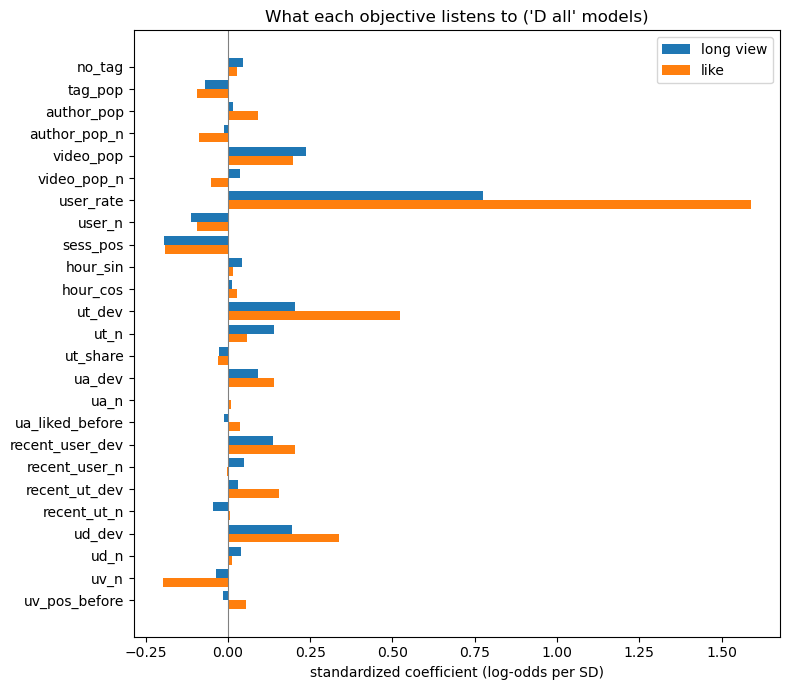

,no_tag,tag_pop,author_pop,author_pop_n,video_pop,video_pop_n,user_rate,user_n,sess_pos,hour_sin,hour_cos,ut_dev,ut_n,ut_share,ua_dev,ua_n,ua_liked_before,recent_user_dev,recent_user_n,recent_ut_dev,recent_ut_n,ud_dev,ud_n,uv_n,uv_pos_before
long view,0.046,-0.069,0.016,-0.013,0.237,0.037,0.775,-0.113,-0.195,0.045,0.012,0.203,0.140,-0.026,0.092,0.001,-0.012,0.138,0.049,0.031,-0.045,0.194,0.039,-0.035,-0.015
like,0.028,-0.093,0.092,-0.087,0.198,-0.050,1.588,-0.093,-0.192,0.016,0.028,0.522,0.057,-0.028,0.141,0.009,0.038,0.204,-0.001,0.154,0.006,0.339,0.012,-0.196,0.056


In [28]:
skip = set(GROUPS["A0"])
co = pd.DataFrame({"long view": std_coefs(models_lv["D all"], cols_all),
                   "like": std_coefs(models_like["D all"], cols_all)})
co = co.loc[[c for c in co.index if c not in skip]]
fig, ax = plt.subplots(figsize=(8, 7))
yy = np.arange(len(co))
ax.barh(yy - 0.2, co["long view"], 0.4, label="long view")
ax.barh(yy + 0.2, co["like"], 0.4, label="like")
ax.set(yticks=yy, yticklabels=co.index, xlabel="standardized coefficient (log-odds per SD)")
ax.axvline(0, color="grey", lw=0.8); ax.invert_yaxis(); ax.legend()
plt.title("What each objective listens to ('D all' models)"); plt.tight_layout(); plt.show()
display(co.round(3).T)

**The two objectives listen to the same signals with different weights.** Coefficients are in log-odds per
standard deviation for targets with very different base rates (31% vs 2%), so we compare their order and
sign rather than their exact size.

* The user's own propensity is the strongest term in both models, about twice as strong for likes (1.59 vs
  0.78).
* **Taste terms weigh relatively more for likes**: user–tag deviation 0.52 vs 0.20, duration taste 0.34 vs
  0.19, author affinity 0.14 vs 0.09, recent user–tag deviation 0.15 vs 0.03.
* **Repeated exposure weighs much more against likes** (−0.20 vs −0.04). The exploration notebook showed that both outcomes are lower on a second showing.
* Video popularity has similar weight in both (0.24 vs 0.20). A later position in the session is associated with lower values of both outcomes, with equal weight (−0.19).
* Some signs look counter-intuitive (for example tag popularity is slightly negative in both models). Tag,
  author and video rates are nested and correlated, so the video-level rate absorbs most of the popularity
  signal.

## 7. Blending the two objectives: what happens to the top 10?

**Setting.** For a sample of test user-days with at least 20 distinct candidate videos, the candidate set
is every distinct video shown to that user that day (first impression kept). To score all candidates
with **the same information**, every history feature is recomputed at a **common instant**: the user's
first block of that day (popularity at the previous hour). The two "D all" models are frozen.

**Blend.** `score_w = (1 − w)·z(logit p_long_view) + w·z(logit p_like)`, with `z` standardizing each
logit over all candidates; `w = 0` ranks for long views only, `w = 1` for likes only. For each `w` we take
the top 10 and count the long views and likes that were actually observed on those videos.

**Limit.** This is a retrospective re-ordering of candidates the recommender had already chosen; their
observed reactions came from a feed ordered by the real system. The effect on a live feed would require an
online experiment.

In [29]:
tq = Q.loc[is_test].copy()
tq["ud"] = tq["user_id"].astype("int64") * 10**8 + tq["date"]
tq = tq.sort_values("time_ms").drop_duplicates(["ud", "video_id"])   # first impression of each video
n_cand = tq.groupby("ud")["video_id"].transform("size")
eligible = np.unique(tq.loc[n_cand >= MIN_CANDIDATES, "ud"])
ud_sample = np.random.default_rng(SEED + 2).choice(eligible, min(TRADEOFF_USER_DAYS, len(eligible)), replace=False)
Q_ci = tq[tq["ud"].isin(ud_sample)].copy()
first = Q_ci.groupby("ud")[["time_ms", "hour_idx", "hourmin"]].transform("min")
Q_ci["t"], Q_ci["h"], Q_ci["hourmin"] = first["time_ms"], first["hour_idx"], first["hourmin"]
Q_ci["sess_pos"] = 0
Q_ci = Q_ci.reset_index(drop=True)
print(f"Eligible user-days: {len(eligible):,}; sampled: {len(ud_sample):,}; candidates: {len(Q_ci):,} "
      f"(median {Q_ci.groupby('ud').size().median():.0f} per user-day, users {Q_ci.user_id.nunique()})")
# Videos must exist at the common instant: drop candidates uploaded after the day of their candidate set.
late = (Q_ci["upload_day"] > Q_ci["day"]).to_numpy()
print("Candidates uploaded after their user-day (dropped):", int(late.sum()))
Q_ci = Q_ci.loc[~late].reset_index(drop=True)

ci_path = CACHE_DIR / f"raw_ci_seed{SEED}_{len(ud_sample)}.parquet"
if USE_CACHE and ci_path.exists():
    R_ci = pd.read_parquet(ci_path)
else:
    R_ci = compute_raw(Q_ci); R_ci.to_parquet(ci_path)

zlog = {}
for target, models in (("lv", models_lv), ("like", models_like)):
    Fc = make_features(R_ci, Q_ci, target, best_m[target], P0[target])
    p = predict(models["D all"], Fc[cols_all])
    zlog[target] = p
    lg = logit(p)
    Q_ci[f"z_{target}"] = (lg - lg.mean()) / lg.std()
    Q_ci[f"p_{target}"] = p
    del Fc
print("Spearman correlation of the two scores within user-day (median):",
      round(Q_ci.groupby("ud")[["z_lv", "z_like"]].corr(method="spearman").xs("z_lv", level=1)["z_like"].median(), 3))

Eligible user-days: 13,434; sampled: 3,000; candidates: 975,406 (median 208 per user-day, users 925)
Candidates uploaded after their user-day (dropped): 0


Spearman correlation of the two scores within user-day (median): -0.215


In [30]:
W_GRID = np.round(np.linspace(0, 1, 11), 2)
top_sets, rows = {}, []
for w in W_GRID:
    s = (1 - w) * Q_ci["z_lv"] + w * Q_ci["z_like"]
    r = s.groupby(Q_ci["ud"]).rank(ascending=False, method="first")
    top = Q_ci[r <= TOP_K]
    top_sets[w] = top.groupby("ud")["video_id"].apply(frozenset)
    agg = top.groupby("ud")[["long_view", "is_like"]].sum()
    rows.append({"w (like weight)": w, "long views in top 10": agg["long_view"].mean(),
                 "likes in top 10": agg["is_like"].mean()})
trade = pd.DataFrame(rows).set_index("w (like weight)")
base_lv = Q_ci.groupby("ud")["long_view"].mean().mean() * TOP_K
base_like = Q_ci.groupby("ud")["is_like"].mean().mean() * TOP_K
trade["Δ long views vs w=0"] = trade["long views in top 10"] - trade.iloc[0, 0]
trade["Δ likes vs w=0"] = trade["likes in top 10"] - trade.iloc[0, 1]
trade["long views lost per like gained"] = -trade["Δ long views vs w=0"] / trade["Δ likes vs w=0"].replace(0, np.nan)
overlap = {w: np.mean([len(a & b) / TOP_K for a, b in zip(top_sets[0.0], top_sets[w])]) for w in W_GRID}
trade["overlap with w=0 top 10"] = pd.Series(overlap)
trade["user-days whose top 10 changed"] = pd.Series({w: np.mean([a != b for a, b in zip(top_sets[0.0], top_sets[w])])
                                                    for w in W_GRID})
print(f"Random top 10 would contain {base_lv:.2f} long views and {base_like:.3f} likes on average")
display(trade.round(3))

Random top 10 would contain 3.95 long views and 0.263 likes on average


,long views in top 10,likes in top 10,Δ long views vs w=0,Δ likes vs w=0,long views lost per like gained,overlap with w=0 top 10,user-days whose top 10 changed
w (like weight),,,,,,,
0.0,5.761,0.164,0.000,0.000,NaN,1.000,0.000
0.1,5.783,0.172,0.022,0.008,-2.680,0.930,0.557
0.2,5.762,0.195,0.001,0.031,-0.043,0.846,0.825
0.3,5.667,0.232,-0.094,0.068,1.377,0.733,0.937
0.4,5.464,0.290,-0.297,0.126,2.366,0.588,0.979
0.5,5.185,0.413,-0.576,0.249,2.316,0.423,0.996
0.6,4.750,0.548,-1.011,0.384,2.632,0.277,0.999
0.7,4.328,0.666,-1.433,0.502,2.856,0.169,1.000
0.8,3.908,0.734,-1.853,0.570,3.248,0.102,1.000


w=0.2: Δ long views    +0.001 per user-day  95% CI [-0.028, +0.029]
w=0.2: Δ likes         +0.031 per user-day  95% CI [+0.020, +0.043]
w=0.5: Δ long views    -0.576 per user-day  95% CI [-0.639, -0.514]
w=0.5: Δ likes         +0.249 per user-day  95% CI [+0.196, +0.304]
w=1.0: Δ long views    -2.530 per user-day  95% CI [-2.638, -2.412]
w=1.0: Δ likes         +0.623 per user-day  95% CI [+0.518, +0.739]


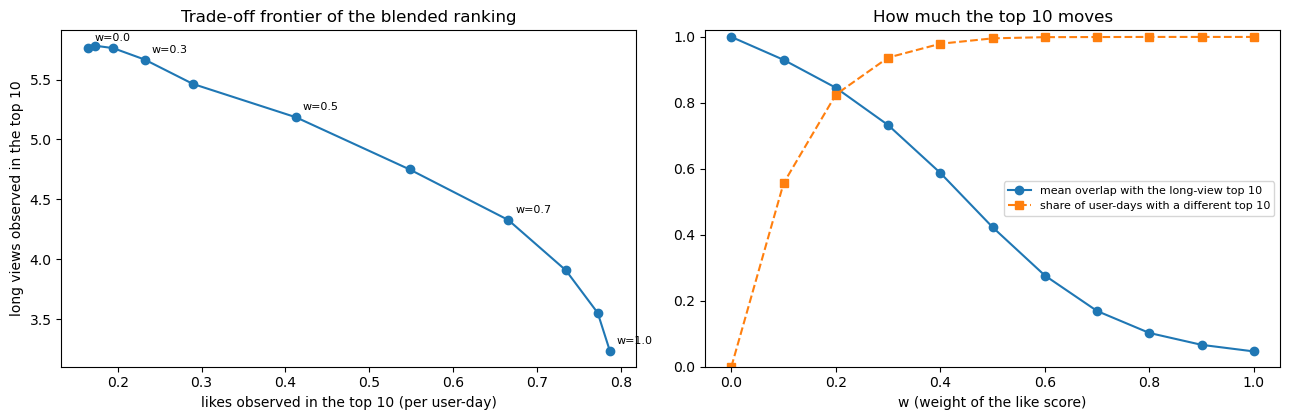

In [31]:
# User-cluster bootstrap for the two extreme rankings and for w = 0.5.
per_ud = {}
for w in (0.0, 0.2, 0.5, 1.0):
    s = (1 - w) * Q_ci["z_lv"] + w * Q_ci["z_like"]
    r = s.groupby(Q_ci["ud"]).rank(ascending=False, method="first")
    per_ud[w] = Q_ci[r <= TOP_K].groupby("ud")[["long_view", "is_like"]].sum()
ud_user = (pd.Series(per_ud[0.0].index, index=per_ud[0.0].index) // 10**8)
users_ci = np.unique(ud_user)
br = np.random.default_rng(SEED)
grp = {u: np.flatnonzero(ud_user.to_numpy() == u) for u in users_ci}
reps = []
for _ in range(N_BOOT):
    idx = np.concatenate([grp[u] for u in br.choice(users_ci, len(users_ci))])
    m0, m2, m5, m1 = (per_ud[w].iloc[idx].mean() for w in (0.0, 0.2, 0.5, 1.0))
    reps.append([m2["long_view"] - m0["long_view"], m2["is_like"] - m0["is_like"],
                 m5["long_view"] - m0["long_view"], m5["is_like"] - m0["is_like"],
                 m1["long_view"] - m0["long_view"], m1["is_like"] - m0["is_like"]])
reps = np.array(reps)
labels = [f"w={w}: Δ {o}" for w in (0.2, 0.5, 1.0) for o in ("long views", "likes")]
points = [trade.loc[w, f"Δ {o} vs w=0"] for w in (0.2, 0.5, 1.0) for o in ("long views", "likes")]
for j, (lab, pt) in enumerate(zip(labels, points)):
    lo, hi = ci(reps[:, j]); print(f"{lab:22s} {pt:+.3f} per user-day  95% CI [{lo:+.3f}, {hi:+.3f}]")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
ax.plot(trade["likes in top 10"], trade["long views in top 10"], "o-")
for w in (0.0, 0.3, 0.5, 0.7, 1.0):
    ax.annotate(f"w={w}", (trade.loc[w, "likes in top 10"], trade.loc[w, "long views in top 10"]),
                textcoords="offset points", xytext=(5, 5), fontsize=8)
ax.set(xlabel="likes observed in the top 10 (per user-day)", ylabel="long views observed in the top 10",
       title="Trade-off frontier of the blended ranking")
ax = axes[1]
ax.plot(W_GRID, trade["overlap with w=0 top 10"], "o-", label="mean overlap with the long-view top 10")
ax.plot(W_GRID, trade["user-days whose top 10 changed"], "s--", label="share of user-days with a different top 10")
ax.set(xlabel="w (weight of the like score)", ylim=(0, 1.02), title="How much the top 10 moves")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### 7.0 Why do the two rankings disagree?

The two *scores* are negatively correlated within a user-day. We check whether the *outcomes* are, and
which kinds of videos each ranking promotes: the duration band and the upload format of the top 10 for
each `w`, next to the observed rates among the candidates. Items with a missing duration are mostly
picture posts (exploration notebook, §4.2).

In [32]:
dur_lab = pd.Categorical([DUR_LABELS[i] for i in Q_ci["dur_bin"]], categories=DUR_LABELS, ordered=True)
mix = {}
for w in (0.0, 0.5, 1.0):
    s = (1 - w) * Q_ci["z_lv"] + w * Q_ci["z_like"]
    r = s.groupby(Q_ci["ud"]).rank(ascending=False, method="first")
    mix[f"top 10, w={w}"] = pd.Series(dur_lab[(r <= TOP_K).to_numpy()]).value_counts(normalize=True)
mix["all candidates"] = pd.Series(dur_lab).value_counts(normalize=True)
mix_t = pd.DataFrame(mix).reindex(DUR_LABELS)
rates = Q_ci.groupby(dur_lab, observed=False)[["long_view", "is_like"]].mean()
mix_t["observed long-view rate"] = rates["long_view"].to_numpy()
mix_t["observed like rate"] = rates["is_like"].to_numpy()
display(mix_t.round(3))

# Outcomes within a user-day
oc = Q_ci.groupby("ud")[["long_view", "is_like"]].corr().xs("long_view", level=1)["is_like"]
print(f"Within user-day correlation of the OUTCOMES (median over user-days with variation): {oc.median():+.3f}; "
      f"P(like | long view) = {Q_ci.loc[Q_ci.long_view == 1, 'is_like'].mean():.3f}, "
      f"P(like | no long view) = {Q_ci.loc[Q_ci.long_view == 0, 'is_like'].mean():.3f}")

fmt_mix = {}
for w in (0.0, 1.0):
    s_ = (1 - w) * Q_ci["z_lv"] + w * Q_ci["z_like"]
    r = s_.groupby(Q_ci["ud"]).rank(ascending=False, method="first")
    fmt_mix[f"top 10, w={w}"] = Q_ci.loc[(r <= TOP_K).to_numpy(), "utype"].astype(str).value_counts(normalize=True)
fmt_mix["all candidates"] = Q_ci["utype"].astype(str).value_counts(normalize=True)
fmt_t = pd.DataFrame(fmt_mix).fillna(0)
fmt_t["observed like rate"] = Q_ci.groupby(Q_ci["utype"].astype(str))["is_like"].mean()
fmt_t["observed long-view rate"] = Q_ci.groupby(Q_ci["utype"].astype(str))["long_view"].mean()
display(fmt_t.sort_values("all candidates", ascending=False).round(3))

,"top 10, w=0.0","top 10, w=0.5","top 10, w=1.0",all candidates,observed long-view rate,observed like rate
missing,0.002,0.006,0.185,0.080,0.116,0.071
<=7s,0.374,0.284,0.034,0.061,0.405,0.017
7-12s,0.279,0.263,0.180,0.189,0.337,0.023
12-18s,0.014,0.023,0.078,0.106,0.278,0.022
18-30s,0.014,0.036,0.098,0.095,0.284,0.021
30-60s,0.053,0.072,0.103,0.118,0.319,0.018
60-120s,0.167,0.191,0.147,0.144,0.374,0.015
120-300s,0.090,0.112,0.147,0.163,0.345,0.011
>300s,0.007,0.011,0.029,0.043,0.299,0.008


Within user-day correlation of the OUTCOMES (median over user-days with variation): +0.049; P(like | long view) = 0.029, P(like | no long view) = 0.018


,"top 10, w=0.0","top 10, w=1.0",all candidates,observed like rate,observed long-view rate
utype,,,,,
LongImport,0.162,0.265,0.275,0.016,0.335
ShortImport,0.422,0.223,0.250,0.025,0.328
Web,0.280,0.103,0.164,0.013,0.381
Kmovie,0.120,0.144,0.159,0.016,0.330
LongPicture,0.002,0.109,0.050,0.072,0.120
ShortCamera,0.002,0.039,0.032,0.017,0.186
Other,0.009,0.072,0.030,0.055,0.205
LongCamera,0.002,0.024,0.025,0.013,0.213
PictureSet,0.000,0.020,0.016,0.032,0.152


**Two robustness checks on the trade-off.**

* *Without items of missing duration.* We drop them from every candidate set and redo the frontier. If the
  conflict were only about picture posts, it would largely disappear.
* *Where do the extra likes at small `w` come from?* For the videos that enter the top 10 at `w = 0.2`,
  we report their rank in the pure long-view ranking (`w = 0`).

Note that `z` standardizes each logit over all candidates pooled, not within a user-day. This only
relabels `w`: the frontier is the same, but `w = 0.5` is not "equal weight" inside a given user-day.

In [33]:
def frontier(frame, grid=(0.0, 0.2, 0.5, 1.0)):
    out = []
    for w in grid:
        s_ = (1 - w) * frame["z_lv"] + w * frame["z_like"]
        r = s_.groupby(frame["ud"]).rank(ascending=False, method="first")
        agg = frame[(r <= TOP_K).to_numpy()].groupby("ud")[["long_view", "is_like"]].sum().mean()
        out.append({"w": w, "long views in top 10": agg["long_view"], "likes in top 10": agg["is_like"]})
    t = pd.DataFrame(out).set_index("w")
    gain = t["likes in top 10"] - t["likes in top 10"].iloc[0]
    loss = t["long views in top 10"].iloc[0] - t["long views in top 10"]
    t["long views lost per like gained"] = (loss / gain).where(t.index > 0)
    return t


no_missing = Q_ci[Q_ci["dur_bin"] > 0]
no_missing = no_missing[no_missing.groupby("ud")["video_id"].transform("size") >= MIN_CANDIDATES]
rho_nm = no_missing.groupby("ud")[["z_lv", "z_like"]].corr(method="spearman").xs("z_lv", level=1)["z_like"].median()
print(f"Without missing-duration items: {no_missing.ud.nunique():,} user-days; "
      f"median Spearman of the two scores {rho_nm:+.3f}")
display(pd.concat({"all candidates": frontier(Q_ci), "without missing duration": frontier(no_missing)}, axis=1).round(3))

r0 = Q_ci["z_lv"].groupby(Q_ci["ud"]).rank(ascending=False, method="first")
s2 = 0.8 * Q_ci["z_lv"] + 0.2 * Q_ci["z_like"]
r2 = s2.groupby(Q_ci["ud"]).rank(ascending=False, method="first")
enter_mask = ((r2 <= TOP_K) & (r0 > TOP_K)).to_numpy()
leave_mask = ((r0 <= TOP_K) & (r2 > TOP_K)).to_numpy()
er = r0[enter_mask]
print(f"Videos entering the top 10 at w=0.2: {enter_mask.sum():,} ({enter_mask.sum() / Q_ci.ud.nunique():.2f} per "
      f"user-day); their rank at w=0: median {er.median():.0f}, 75th pct {er.quantile(0.75):.0f}, "
      f"share within ranks 11-20: {(er <= 20).mean():.2f}")
print(f"Observed rates — entering videos: like {Q_ci.loc[enter_mask, 'is_like'].mean():.3f}, "
      f"long view {Q_ci.loc[enter_mask, 'long_view'].mean():.3f}; replaced videos: like "
      f"{Q_ci.loc[leave_mask, 'is_like'].mean():.3f}, long view {Q_ci.loc[leave_mask, 'long_view'].mean():.3f}")

Without missing-duration items: 2,982 user-days; median Spearman of the two scores -0.186


all candidates                                                 without missing duration                                                
    long views in top 10 likes in top 10 long views lost per like gained     long views in top 10 likes in top 10 long views lost per like gained
w                                                                                                                                                
0.0                5.761           0.164                             NaN                    5.760           0.161                             NaN
0.2                5.762           0.195                          -0.043                    5.762           0.192                          -0.088
0.5                5.185           0.413                           2.316                    5.187           0.404                           2.353
1.0                3.231           0.787                           4.060                    3.583           0.633                           4.616

Videos entering the top 10 at w=0.2: 4,625 (1.54 per user-day); their rank at w=0: median 14, 75th pct 18, share within ranks 11-20: 0.84
Observed rates — entering videos: like 0.030, long view 0.545; replaced videos: like 0.010, long view 0.544


**The exchange rate between the two objectives.** On 3,000 sampled user-days (925 users, a median of 208
candidates each):

* **The outcomes agree, the models do not.** On the same candidates, a long-viewed video is liked more
  often (2.9% vs 1.8%; within-user-day correlation +0.05). Yet the two *scores* are negatively correlated
  (median Spearman −0.22). The long-view model fills the top 10 with clips of 12 s or less (65% vs 25% of
  candidates), where a long view only requires a full watch of a very short video, mostly `ShortImport` and
  `Web` uploads. The like model avoids the shortest clips (3% ≤ 7 s) and promotes items with a missing duration, mostly picture posts (19% of its top 10 vs 8% of candidates, like rate 7.1%); above 12 s its duration mix is close to that of the candidates. Removing
  missing-duration items leaves the score correlation almost unchanged (−0.19), so picture posts are not
  the main cause. The divergence comes from what each model learned to favour, especially short clips for
  the long-view model, not from opposite user behaviour.
* Ranking for long views puts **5.76 long views and 0.164 likes** in the top 10, fewer likes than a random
  top 10 (0.263). Ranking for likes gives **3.23 long views and 0.787 likes**: +0.62 likes for −2.53 long
  views, about **4 long views per like** at the extreme.
* **The first likes are almost free.** At `w = 0.2` the top 10 gains +0.031 likes [0.020, 0.043], +19%,
  with no detectable loss of long views (+0.001 [−0.028, +0.029]). The swaps involve 1.5 videos per
  user-day, which came from just outside the top 10 (median rank 14, 84% from ranks 11–20). The incoming
  videos are as often long-viewed as the ones they replace (54.5% vs 54.4%) but three times as often liked
  (3.0% vs 1.0%). We chose `w = 0.2` after scanning 11 weights, so this point should be confirmed on another
  sample. At `w = 0.5` the price becomes **2.3 long views per like** (+0.25 likes [0.20, 0.30], −0.58 long
  views [−0.64, −0.51]).
* **How much the top 10 moves.** At `w = 0.2` the top 10 changes for 82% of user-days, but 85% of the
  videos stay. At `w = 0.5` almost every top 10 changes and 42% of the videos remain. At `w = 1` only 5%
  remain. The abstract asked whether the two rankings would be almost identical: beyond a light blend,
  they are not.

These are counts of reactions observed under the real feed, re-ordered retrospectively. They measure how
well each score *identifies* videos that obtained each reaction, not what a live re-ranking would produce.

### 7.1 One user-day, two rankings side by side

A user-day drawn at random (fixed seed) among those whose top 10 changes between `w = 0` and `w = 1`.

In [34]:
changed = [ud for ud, a, b in zip(top_sets[0.0].index, top_sets[0.0], top_sets[1.0]) if a != b]
ud_ex = np.random.default_rng(SEED + 3).choice(changed)
ex = Q_ci[Q_ci["ud"] == ud_ex].copy()
ex["rank LV"] = ex["z_lv"].rank(ascending=False, method="first").astype(int)
ex["rank like"] = ex["z_like"].rank(ascending=False, method="first").astype(int)
ex["tags"] = [f"{a}" + (f",{c}" if c >= 0 else "") for a, c in zip(ex["tag1"], ex["tag2"])]
ex["duration"] = [DUR_LABELS[i] for i in ex["dur_bin"]]
cols_show = ["video_id", "tags", "duration", "p_lv", "p_like", "long_view", "is_like"]
left = ex.sort_values("rank LV").head(TOP_K)[cols_show].reset_index(drop=True)
right = ex.sort_values("rank like").head(TOP_K)[cols_show].reset_index(drop=True)
display(Markdown(f"User {ud_ex // 10**8}, date {ud_ex % 10**8} — {len(ex)} candidates; "
                 f"{len(set(left.video_id) & set(right.video_id))} of 10 videos in common"))
display(pd.concat({"ranked for long view (w=0)": left, "ranked for like (w=1)": right}, axis=1).round(3))

User 931, date 20220428 — 174 candidates; 0 of 10 videos in common

ranked for long view (w=0)                                               ranked for like (w=1)                                               
                    video_id tags duration   p_lv p_like long_view is_like              video_id tags  duration   p_lv p_like long_view is_like
0                    3215380   28     <=7s  0.661  0.005         0       0               2399001   11     >300s  0.288  0.087         0       0
1                     955039    8     <=7s  0.616  0.010         0       0               1027834    2  120-300s  0.307  0.031         0       0
2                     879847    8     <=7s  0.600  0.010         1       0               2405790    2  120-300s  0.306  0.031         0       0
3                    3431733    7     <=7s  0.579  0.006         1       0                244987   34     7-12s  0.295  0.027         1       0
4                    2623859    7    7-12s  0.551  0.008         1       0               2098644    2  120-300s  0.293  0.026         0       0
5                    2233652    8    7-12s  0.543  0.006         0       0                278193    2  120-300s  0.290  0.026         0       0
6                    3645354    8    7-12s  0.543  0.009         1       0               2919170   34     7-12s  0.339  0.026         0       0
7                    1769192   -1     <=7s  0.536  0.012         0       0               1005206    2     >300s  0.353  0.025         0       0
8                     691947   11     <=7s  0.535  0.012         0       0               1529087    2  120-300s  0.322  0.025         0       0
9                    2330269   -1     <=7s  0.533  0.012         1       0               3046614   34     7-12s  0.220  0.025         0       0

**The same user, two feeds.** The two top 10s of this user-day have no video in common. The long-view ranking
is made of clips of 12 seconds or less (tags 7, 8, 28), and five of them were long-viewed. The like ranking
prefers 2–5+ minute videos, mostly tag 2, plus three short tag-34 clips. Only one of them was long-viewed,
and none of the twenty videos was liked. This single user-day illustrates the divergence of §7.0. Note
that preferring long videos is specific to this user's like history. Across all candidates, like rates
*decrease* with duration above 12 s.

## 8. Conclusions

**Main project: what personalization adds to popularity (long view, tab 1).**

1. *Content and popularity* set most of the ranking quality. The block AUC goes from 0.586 (duration and
   format) to 0.622 with popularity rebuilt from past logs. That popularity comes from only 1,000 users,
   so it is a weak baseline.
2. *User propensity* (B) is the largest gain for **predicting individuals** (log-loss 0.587 → 0.536), but
   it cannot reorder a block. Its small within-block effect is a fitting artefact: a within-block estimator reaches the same level with no user feature at all (A 0.633 vs pointwise A 0.623).
3. *Personal taste* gives a small, clearly non-zero gain in **ranking**: +0.015 block AUC for "D all" over B
   [0.014, 0.017], and +1.7 points [1.5, 1.9] in the share of mixed-outcome requests whose first video is long-viewed. The
   gain is confirmed by a within-block estimator, with equal weight per user, and on new videos (81% of
   impressions). The user–tag rate carries most of it, followed by author affinity and duration taste.
   Recent history and repeated exposure add almost nothing to the ordering.
4. On **random exposures** the user–tag signal is about five times stronger (user AUC +0.043 vs +0.008),
   but probabilities trained on the feed are badly miscalibrated there (35% predicted vs 8.5% observed).
5. A boosted-tree model on the same features adds only +0.0025 in the feed and ranks random exposures
   worse. The linear ladder answers the question.

**3-ECTS extension: likes and the blend.**

6. Likes depend first on *who* the user is (global AUC 0.93). Within a request, content popularity and
   personal taste both matter. The personal step is larger than for long views (+0.046 block AUC for
   "D all" over B), on a much smaller set of blocks.
7. Long views and likes are mildly *positively* related in the outcomes, but the two models rank
   candidates very differently (Spearman −0.22). The long-view model favours very short clips, where a long view is easy; the like model avoids very short clips and favours missing-duration (picture) items.
8. The exchange rate is non-linear. A light blend (`w ≈ 0.2`) adds about 19% more likes with no
   detectable loss of long views. Halfway costs about 2.3 long views per like, and ranking for likes alone
   about 4.

**Limits.** Retrospective evaluation on candidates chosen by the production system; 1,000 users only;
the training rows are a 40% sample of blocks (memory); the order of viewing inside a block is unknown; the
blend weight was selected on the same sample on which it is reported. A live A/B test would be needed to
estimate the effect on real engagement.

**Possible next steps.** A within-block (pairwise or listwise) learning-to-rank objective. Recalibrating
scores on random exposures. Defining the long-view target relative to duration, so that it no longer
rewards very short clips. Repeating the blend with a held-out sample of user-days.

In [35]:
print(f"Total runtime: {(time.time() - T_START) / 60:.1f} min")

Total runtime: 21.1 min
